**Cell-1 — DINOv3 Environment & GPU Setup**

In [ ]:
# ============================================================
# CELL-1 — DINOv3 ENVIRONMENT & GPU SETUP
# ============================================================

import sys
import platform
import torch
import torchvision

print("=" * 70)
print("DINOv3 — ENVIRONMENT CHECK")
print("=" * 70)

print("\nPython:")
print(sys.version)

print("\nPyTorch:")
print(torch.__version__)

print("\nTorchvision:")
print(torchvision.__version__)

print("\nCUDA available:")
print(torch.cuda.is_available())

if torch.cuda.is_available():

    device = torch.device("cuda")

    print("\nGPU:")
    print(torch.cuda.get_device_name(0))

    print("\nCUDA version:")
    print(torch.version.cuda)

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(
        f"\nGPU memory: {gpu_memory:.2f} GB"
    )

else:

    device = torch.device("cpu")

    print("\n⚠️ CUDA is not available.")

print("\nSelected device:")
print(device)

print("\nPlatform:")
print(platform.platform())

print("\n" + "=" * 70)

if device.type == "cuda":
    print("✓ GPU environment is ready.")
else:
    print("⚠️ GPU is not available. Do not continue yet.")

DINOv3 — ENVIRONMENT CHECK

Python:
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]

PyTorch:
2.11.0+cu128

Torchvision:
0.26.0+cu128

CUDA available:
True

GPU:
Tesla T4

CUDA version:
12.8

GPU memory: 14.56 GB

Selected device:
cuda

Platform:
Linux-6.6.122+-x86_64-with-glibc2.39

✓ GPU environment is ready.


**Cell-2 — Verify DINOv2 checkpoint and architecture**

In [ ]:
# ============================================================
# CELL-2 — DINOv2 Checkpoint & Architecture Verification
# ============================================================

import torch
from transformers import AutoImageProcessor, AutoModel

MODEL_ID = "facebook/dinov2-small"

print("=" * 70)
print("DINOv2 CHECKPOINT VERIFICATION")
print("=" * 70)

print(f"Model ID: {MODEL_ID}")
print(f"Transformers: {__import__('transformers').__version__}")
print()

# Load image processor
processor = AutoImageProcessor.from_pretrained(MODEL_ID)

# Load pretrained DINOv2 model
model = AutoModel.from_pretrained(MODEL_ID)

# Move to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Parameter statistics
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("✓ Checkpoint loaded successfully")
print(f"✓ Device: {device}")
print(f"✓ Total parameters: {total_params / 1e6:.2f} M")
print(f"✓ Trainable parameters: {trainable_params / 1e6:.2f} M")
print()

# Architecture information
print("Model configuration:")
print(f"  Hidden size       : {model.config.hidden_size}")
print(f"  Image size        : {model.config.image_size}")
print(f"  Patch size        : {model.config.patch_size}")
print(f"  Num hidden layers : {model.config.num_hidden_layers}")
print()

# Quick tensor sanity check
dummy_image = torch.randn(1, 3, 224, 224).to(device)

with torch.no_grad():
    outputs = model(pixel_values=dummy_image)

print("Forward-pass sanity check:")
print(f"  Last hidden state : {tuple(outputs.last_hidden_state.shape)}")

if hasattr(outputs, "pooler_output") and outputs.pooler_output is not None:
    print(f"  Pooler output     : {tuple(outputs.pooler_output.shape)}")

print()
print("✓ DINOv2 is ready for the next stage.")
print("=" * 70)

DINOv2 CHECKPOINT VERIFICATION
Model ID: facebook/dinov2-small
Transformers: 5.16.1



preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

✓ Checkpoint loaded successfully
✓ Device: cuda
✓ Total parameters: 22.06 M
✓ Trainable parameters: 22.06 M

Model configuration:
  Hidden size       : 384
  Image size        : 518
  Patch size        : 14
  Num hidden layers : 12

Forward-pass sanity check:
  Last hidden state : (1, 257, 384)
  Pooler output     : (1, 384)

✓ DINOv2 is ready for the next stage.


**Cell-3 — Kaggle authentication via KAGGLE_API_TOKEN**

In [ ]:
# ============================================================
# CELL-3 — Kaggle Authentication via Colab Secret
# ============================================================

import os
from google.colab import userdata
from kaggle.api.kaggle_api_extended import KaggleApi

print("=" * 70)
print("KAGGLE AUTHENTICATION")
print("=" * 70)

# Retrieve the existing Kaggle API token securely
KAGGLE_API_TOKEN = userdata.get("KAGGLE_API_TOKEN")

# Kaggle CLI expects this token through the environment
os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

# Authenticate
api = KaggleApi()
api.authenticate()

print("✓ Kaggle authentication successful")
print("=" * 70)

KAGGLE AUTHENTICATION
✓ Kaggle authentication successful


**Cell-4 — Download and extract the exact dataset**

In [ ]:
# ============================================================
# CELL-4 — Download & Extract PlantVillage Dataset
# ============================================================

import os
import glob
import zipfile

KAGGLE_DATASET = "tushar5harma/plant-village-dataset-updated"
DOWNLOAD_DIR = "/content/kaggle_data"
EXTRACT_DIR = "/content/plant_village"

os.makedirs(DOWNLOAD_DIR, exist_ok=True)
os.makedirs(EXTRACT_DIR, exist_ok=True)

print("=" * 70)
print("DOWNLOADING PLANTVILLAGE DATASET")
print("=" * 70)

print(f"Dataset : {KAGGLE_DATASET}")
print(f"Download: {DOWNLOAD_DIR}")
print()

# Download using the already authenticated API
api.dataset_download_files(
    KAGGLE_DATASET,
    path=DOWNLOAD_DIR,
    unzip=False
)

print("✓ Dataset archive downloaded")

# Find downloaded ZIP
archives = glob.glob(os.path.join(DOWNLOAD_DIR, "*.zip"))

if not archives:
    raise FileNotFoundError("No dataset ZIP file found.")

zip_path = archives[0]

print(f"✓ Archive: {os.path.basename(zip_path)}")
print(f"✓ Size   : {os.path.getsize(zip_path) / (1024**2):.2f} MB")

# Extract
print("\nExtracting dataset...")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(EXTRACT_DIR)

print("✓ Extraction completed")

# Show top-level structure
print("\nExtracted structure:")

for item in sorted(os.listdir(EXTRACT_DIR)):
    path = os.path.join(EXTRACT_DIR, item)

    if os.path.isdir(path):
        print(f"  📁 {item}/")
    else:
        print(f"  📄 {item}")

print("\n" + "=" * 70)
print("✓ DATASET READY")
print("=" * 70)

DOWNLOADING PLANTVILLAGE DATASET
Dataset : tushar5harma/plant-village-dataset-updated
Download: /content/kaggle_data

Dataset URL: https://www.kaggle.com/datasets/tushar5harma/plant-village-dataset-updated
✓ Dataset archive downloaded
✓ Archive: plant-village-dataset-updated.zip
✓ Size   : 1026.37 MB

Extracting dataset...
✓ Extraction completed

Extracted structure:
  📁 Apple/
  📁 Bell Pepper/
  📁 Cherry/
  📁 Corn (Maize)/
  📁 Grape/
  📁 Peach/
  📁 Potato/
  📁 Strawberry/
  📁 Tomato/

✓ DATASET READY


**Cell-5 — Verify dataset structure and class counts**

In [ ]:
# ============================================================
# CELL-5 — Dataset Structure & Class Verification
# ============================================================

import os
from pathlib import Path
from collections import defaultdict

DATASET_ROOT = Path("/content/plant_village")

EXPECTED_SPECIES = [
    "Apple",
    "Bell Pepper",
    "Cherry",
    "Corn (Maize)",
    "Grape",
    "Peach",
    "Potato",
    "Strawberry",
    "Tomato",
]

print("=" * 70)
print("PLANTVILLAGE DATASET STRUCTURE VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# Species verification
# ------------------------------------------------------------

species_dirs = sorted([
    p for p in DATASET_ROOT.iterdir()
    if p.is_dir()
])

print(f"\nSpecies directories found: {len(species_dirs)}")

for p in species_dirs:
    print(f"  ✓ {p.name}")

# ------------------------------------------------------------
# Split and class inspection
# ------------------------------------------------------------

split_counts = defaultdict(int)
class_counts = defaultdict(int)

print("\nDetailed structure:\n")

for species_dir in species_dirs:

    print(f"📁 {species_dir.name}/")

    split_dirs = sorted([
        p for p in species_dir.iterdir()
        if p.is_dir()
    ])

    for split_dir in split_dirs:

        print(f"   ├── {split_dir.name}/")

        class_dirs = sorted([
            p for p in split_dir.iterdir()
            if p.is_dir()
        ])

        split_counts[split_dir.name] += 1

        for class_dir in class_dirs:

            image_count = sum(
                1 for f in class_dir.iterdir()
                if f.is_file()
            )

            class_name = f"{species_dir.name}__{class_dir.name}"

            class_counts[class_name] += image_count

            print(
                f"   │   └── {class_dir.name}: "
                f"{image_count:,} images"
            )

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(f"Species : {len(species_dirs)}")
print(f"Unique global classes : {len(class_counts)}")

print("\nSplit directory occurrences:")
for split, count in sorted(split_counts.items()):
    print(f"  {split}: {count}")

print("\nImages by global class:")
for i, (cls, count) in enumerate(sorted(class_counts.items())):
    print(f"  {i:02d}  {cls:<55} {count:,}")

print("\n" + "=" * 70)
print("✓ STRUCTURE VERIFICATION COMPLETED")
print("=" * 70)

PLANTVILLAGE DATASET STRUCTURE VERIFICATION

Species directories found: 9
  ✓ Apple
  ✓ Bell Pepper
  ✓ Cherry
  ✓ Corn (Maize)
  ✓ Grape
  ✓ Peach
  ✓ Potato
  ✓ Strawberry
  ✓ Tomato

Detailed structure:

📁 Apple/
   ├── Test/
   │   └── Apple Scab: 51 images
   │   └── Black Rot: 50 images
   │   └── Cedar Apple Rust: 44 images
   │   └── Healthy: 51 images
   ├── Train/
   │   └── Apple Scab: 2,016 images
   │   └── Black Rot: 1,987 images
   │   └── Cedar Apple Rust: 1,760 images
   │   └── Healthy: 2,008 images
   ├── Val/
   │   └── Apple Scab: 453 images
   │   └── Black Rot: 447 images
   │   └── Cedar Apple Rust: 396 images
   │   └── Healthy: 451 images
📁 Bell Pepper/
   ├── Test/
   │   └── Bacterial Spot: 48 images
   │   └── Healthy: 50 images
   ├── Train/
   │   └── Bacterial Spot: 1,913 images
   │   └── Healthy: 1,988 images
   ├── Val/
   │   └── Bacterial Spot: 430 images
   │   └── Healthy: 447 images
📁 Cherry/
   ├── Test/
   │   └── Healthy: 46 images
   │   └── 

**Cell-6 — Build reproducible manifest + class mapping**

In [ ]:
# ============================================================
# CELL-6 — Build Manifest & Global Class Mapping
# ============================================================

import os
import json
import pandas as pd
from pathlib import Path

DATASET_ROOT = Path("/content/plant_village")
MANIFEST_DIR = Path("/content/dinov2_manifest")
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

records = []

# ------------------------------------------------------------
# Collect image records
# ------------------------------------------------------------

for species_dir in sorted(DATASET_ROOT.iterdir()):

    if not species_dir.is_dir():
        continue

    species = species_dir.name.strip()

    for split_dir in sorted(species_dir.iterdir()):

        if not split_dir.is_dir():
            continue

        split = split_dir.name.strip().lower()

        if split not in {"train", "val", "test"}:
            continue

        for disease_dir in sorted(split_dir.iterdir()):

            if not disease_dir.is_dir():
                continue

            # Normalize accidental whitespace
            disease = disease_dir.name.strip()

            global_class = f"{species}__{disease}"

            for image_path in sorted(disease_dir.iterdir()):

                if (
                    image_path.is_file()
                    and image_path.suffix.lower() in VALID_EXTENSIONS
                ):
                    records.append({
                        "path": str(image_path),
                        "species": species,
                        "disease": disease,
                        "class_name": global_class,
                        "split": split,
                    })

# ------------------------------------------------------------
# Create DataFrame
# ------------------------------------------------------------

df = pd.DataFrame(records)

if df.empty:
    raise RuntimeError("No images were found.")

# ------------------------------------------------------------
# Global class mapping
# ------------------------------------------------------------

class_names = sorted(df["class_name"].unique())

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

df["label"] = df["class_name"].map(class_to_idx)

# ------------------------------------------------------------
# Save manifest and mapping
# ------------------------------------------------------------

manifest_path = MANIFEST_DIR / "image_manifest.csv"
mapping_path = MANIFEST_DIR / "class_mapping.json"

df.to_csv(manifest_path, index=False)

with open(mapping_path, "w") as f:
    json.dump(
        {
            "class_to_idx": class_to_idx,
            "idx_to_class": {
                str(k): v for k, v in idx_to_class.items()
            }
        },
        f,
        indent=2
    )

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("=" * 70)
print("DINOv2 MANIFEST CREATED")
print("=" * 70)

print(f"\nTotal images : {len(df):,}")
print(f"Classes      : {len(class_names)}")

print("\nSplit distribution:")
print(df["split"].value_counts().sort_index())

print("\nClass distribution:")
print(
    df.groupby(["split", "class_name"])
      .size()
      .unstack(fill_value=0)
      .T
      .to_string()
)

print("\nClass mapping:")
for idx, class_name in enumerate(class_names):
    print(f"{idx:02d}  {class_name}")

print("\nSaved files:")
print(f"  ✓ {manifest_path}")
print(f"  ✓ {mapping_path}")

print("\n" + "=" * 70)
print("✓ MANIFEST READY")
print("=" * 70)

DINOv2 MANIFEST CREATED

Total images : 67,111
Classes      : 29

Split distribution:
split
test      1354
train    53690
val      12067
Name: count, dtype: int64

Class distribution:
split                               test  train  val
class_name                                          
Apple__Apple Scab                     51   2016  453
Apple__Black Rot                      50   1987  447
Apple__Cedar Apple Rust               44   1760  396
Apple__Healthy                        51   2008  451
Bell Pepper__Bacterial Spot           48   1913  430
Bell Pepper__Healthy                  50   1988  447
Cherry__Healthy                       46   1826  410
Cherry__Powdery Mildew                43   1683  378
Corn (Maize)__Cercospora Leaf Spot    41   1642  369
Corn (Maize)__Common Rust             48   1907  429
Corn (Maize)__Healthy                 47   1859  418
Corn (Maize)__Northern Leaf Blight    48   1908  429
Grape__Black Rot                      48   1888  424
Grape__Esca (Black Me

**Cell-7 — Identify the 7 excluded files**

In [ ]:
# ============================================================
# CELL-7 — Identify Files Excluded from Manifest
# ============================================================

from pathlib import Path

DATASET_ROOT = Path("/content/plant_village")
VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

excluded = []

for path in DATASET_ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() not in VALID_EXTENSIONS:
        excluded.append(path)

print("=" * 70)
print("MANIFEST INTEGRITY CHECK")
print("=" * 70)

print(f"\nFiles excluded due to unsupported extensions: {len(excluded)}")

for path in excluded:
    print(f"  {path}")

print("\n" + "=" * 70)

if len(excluded) == 0:
    print("✓ No unsupported files found.")
elif len(excluded) == 7:
    print("✓ Exactly 7 excluded files identified.")
else:
    print("⚠ Unexpected exclusion count — investigate before training.")

print("=" * 70)

MANIFEST INTEGRITY CHECK

Files excluded due to unsupported extensions: 0

✓ No unsupported files found.


**Cell-8 — Build DINOv2 processor + Dataset/DataLoaders**

In [ ]:
# ============================================================
# CELL-8 — DINOv2 Processor, Dataset & DataLoaders
# ============================================================

import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

MODEL_ID = "facebook/dinov2-small"
MANIFEST_PATH = "/content/dinov2_manifest/image_manifest.csv"

BATCH_SIZE = 32
NUM_WORKERS = 2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# Load manifest
# ------------------------------------------------------------

df = pd.read_csv(MANIFEST_PATH)

# ------------------------------------------------------------
# Load official DINOv2 image processor
# ------------------------------------------------------------

processor = AutoImageProcessor.from_pretrained(MODEL_ID)

print("=" * 70)
print("DINOV2 DATA PIPELINE")
print("=" * 70)

print(f"Model ID       : {MODEL_ID}")
print(f"Device         : {device}")
print(f"Batch size     : {BATCH_SIZE}")
print(f"Workers        : {NUM_WORKERS}")

print("\nProcessor configuration:")
print(processor)

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class PlantVillageDataset(Dataset):

    def __init__(self, dataframe, processor):
        self.df = dataframe.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")

        encoded = self.processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = encoded["pixel_values"].squeeze(0)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return {
            "pixel_values": pixel_values,
            "labels": label
        }

# ------------------------------------------------------------
# Split datasets
# ------------------------------------------------------------

train_df = df[df["split"] == "train"].copy()
val_df   = df[df["split"] == "val"].copy()
test_df  = df[df["split"] == "test"].copy()

train_dataset = PlantVillageDataset(train_df, processor)
val_dataset   = PlantVillageDataset(val_df, processor)
test_dataset  = PlantVillageDataset(test_df, processor)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

# ------------------------------------------------------------
# Sanity check
# ------------------------------------------------------------

batch = next(iter(train_loader))

print("\nDataLoader sizes:")
print(f"  Train batches : {len(train_loader):,}")
print(f"  Val batches   : {len(val_loader):,}")
print(f"  Test batches  : {len(test_loader):,}")

print("\nFirst training batch:")
print(f"  pixel_values shape : {tuple(batch['pixel_values'].shape)}")
print(f"  labels shape       : {tuple(batch['labels'].shape)}")
print(f"  pixel dtype        : {batch['pixel_values'].dtype}")
print(f"  label dtype        : {batch['labels'].dtype}")

print("\n" + "=" * 70)
print("✓ DINOv2 DATA PIPELINE READY")
print("=" * 70)

DINOV2 DATA PIPELINE
Model ID       : facebook/dinov2-small
Device         : cuda
Batch size     : 32
Workers        : 2

Processor configuration:
BitImageProcessor {
  "crop_size": {
    "height": 224,
    "width": 224
  },
  "do_center_crop": true,
  "do_convert_rgb": true,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.485,
    0.456,
    0.406
  ],
  "image_processor_type": "BitImageProcessor",
  "image_std": [
    0.229,
    0.224,
    0.225
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 256
  }
}


DataLoader sizes:
  Train batches : 1,678
  Val batches   : 378
  Test batches  : 43

First training batch:
  pixel_values shape : (32, 3, 224, 224)
  labels shape       : (32,)
  pixel dtype        : torch.float32
  label dtype        : torch.int64

✓ DINOv2 DATA PIPELINE READY


**Cell-9 — Freeze DINOv2 + feature extraction sanity check**

In [ ]:
# ============================================================
# CELL-9 — Frozen DINOv2 Feature Extraction Sanity Check
# ============================================================

import torch

# ------------------------------------------------------------
# Freeze DINOv2
# ------------------------------------------------------------

model.eval()

for param in model.parameters():
    param.requires_grad = False

print("=" * 70)
print("DINOV2 FROZEN FEATURE EXTRACTOR")
print("=" * 70)

print(f"Model parameters : {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")
print(f"Trainable params : {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f} M")

# ------------------------------------------------------------
# Move a batch to GPU
# ------------------------------------------------------------

pixel_values = batch["pixel_values"].to(
    device,
    non_blocking=True
)

labels = batch["labels"].to(
    device,
    non_blocking=True
)

# ------------------------------------------------------------
# Extract CLS features
# ------------------------------------------------------------

with torch.inference_mode():

    outputs = model(
        pixel_values=pixel_values
    )

    features = outputs.pooler_output

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

print("\nFeature extraction:")
print(f"  Input shape    : {tuple(pixel_values.shape)}")
print(f"  Feature shape  : {tuple(features.shape)}")
print(f"  Label shape    : {tuple(labels.shape)}")
print(f"  Feature dtype  : {features.dtype}")

print("\nFeature statistics:")
print(f"  Mean           : {features.mean().item():.6f}")
print(f"  Std            : {features.std().item():.6f}")
print(f"  Min            : {features.min().item():.6f}")
print(f"  Max            : {features.max().item():.6f}")

print("\nGradient check:")
print(f"  Any trainable parameters? : {any(p.requires_grad for p in model.parameters())}")
print(f"  Features require grad?    : {features.requires_grad}")

print("\n" + "=" * 70)
print("✓ FROZEN FEATURE EXTRACTION VERIFIED")
print("=" * 70)

DINOV2 FROZEN FEATURE EXTRACTOR
Model parameters : 22.06 M
Trainable params : 0.00 M

Feature extraction:
  Input shape    : (32, 3, 224, 224)
  Feature shape  : (32, 384)
  Label shape    : (32,)
  Feature dtype  : torch.float32

Feature statistics:
  Mean           : 0.000906
  Std            : 2.432604
  Min            : -9.718436
  Max            : 9.847217

Gradient check:
  Any trainable parameters? : False
  Features require grad?    : False

✓ FROZEN FEATURE EXTRACTION VERIFIED


**Cell-10 — Build the 29-class classifier head**

In [ ]:
# ============================================================
# CELL-10 — DINOv2 384 → 29 Classifier Head
# ============================================================

import torch
import torch.nn as nn

NUM_CLASSES = 29
FEATURE_DIM = 384

# ------------------------------------------------------------
# Classifier
# ------------------------------------------------------------

classifier = nn.Linear(
    FEATURE_DIM,
    NUM_CLASSES
).to(device)

# ------------------------------------------------------------
# Parameter summary
# ------------------------------------------------------------

total_classifier_params = sum(
    p.numel() for p in classifier.parameters()
)

trainable_classifier_params = sum(
    p.numel()
    for p in classifier.parameters()
    if p.requires_grad
)

print("=" * 70)
print("DINOV2 CLASSIFIER HEAD")
print("=" * 70)

print(f"Input features    : {FEATURE_DIM}")
print(f"Output classes    : {NUM_CLASSES}")
print(f"Classifier        : Linear({FEATURE_DIM}, {NUM_CLASSES})")
print(f"Total parameters  : {total_classifier_params:,}")
print(f"Trainable params  : {trainable_classifier_params:,}")

# ------------------------------------------------------------
# Forward-pass sanity check
# ------------------------------------------------------------

classifier.eval()

with torch.inference_mode():

    logits = classifier(features)

print("\nForward-pass sanity check:")
print(f"  Feature shape : {tuple(features.shape)}")
print(f"  Logits shape  : {tuple(logits.shape)}")
print(f"  Logits dtype  : {logits.dtype}")

# ------------------------------------------------------------
# Verify output dimension
# ------------------------------------------------------------

assert logits.shape == (32, NUM_CLASSES)

print("\n✓ Output dimension verified: 29 classes")
print("✓ Classifier head ready for training")

print("=" * 70)

DINOV2 CLASSIFIER HEAD
Input features    : 384
Output classes    : 29
Classifier        : Linear(384, 29)
Total parameters  : 11,165
Trainable params  : 11,165

Forward-pass sanity check:
  Feature shape : (32, 384)
  Logits shape  : (32, 29)
  Logits dtype  : torch.float32

✓ Output dimension verified: 29 classes
✓ Classifier head ready for training


**Cell-11A — Stabilize the DataLoaders**

In [ ]:
# ============================================================
# CELL-11A — Rebuild DataLoaders for Stable DINOv2 Training
# ============================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("=" * 70)
print("DATALOADERS REBUILT")
print("=" * 70)

print(f"Train batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")
print(f"Test batches  : {len(test_loader)}")
print(f"Batch size    : {BATCH_SIZE}")
print(f"Workers       : 0")
print(f"Pin memory    : True")
print("=" * 70)

DATALOADERS REBUILT
Train batches : 1678
Val batches   : 378
Test batches  : 43
Batch size    : 32
Workers       : 0
Pin memory    : True


**Cell-11 — Train frozen DINOv2 classifier**

In [ ]:
# ============================================================
# CELL-11 — DINOv2 Frozen-Feature Baseline Training
#            + Live Batch Progress
#            PyTorch 2.11 compatible
# ============================================================

import copy
import time
import torch
import torch.nn as nn
from torch.optim import AdamW
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

NUM_EPOCHS = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1

BEST_CHECKPOINT = "/content/dinov2_linear_best.pth"

# ------------------------------------------------------------
# Loss + optimizer
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

optimizer = AdamW(
    classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Current PyTorch AMP API
scaler = torch.amp.GradScaler("cuda")

best_val_acc = 0.0
best_state = None

history = []

# ------------------------------------------------------------
# Frozen DINOv2 feature extraction
# ------------------------------------------------------------

def extract_features(pixel_values):

    with torch.inference_mode():

        outputs = model(
            pixel_values=pixel_values
        )

        return outputs.pooler_output


# ============================================================
# TRAINING
# ============================================================

print("=" * 70)
print("DINOV2 FROZEN-FEATURE BASELINE TRAINING")
print("=" * 70)

print(f"Epochs          : {NUM_EPOCHS}")
print(f"Learning rate   : {LEARNING_RATE}")
print(f"Weight decay    : {WEIGHT_DECAY}")
print(f"Label smoothing : {LABEL_SMOOTHING}")
print(f"Backbone        : FROZEN")
print(f"AMP             : CUDA")
print()

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    classifier.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS} [TRAIN]",
        unit="batch",
        dynamic_ncols=True
    )

    for batch_data in train_bar:

        pixel_values = batch_data["pixel_values"].to(
            device,
            non_blocking=True
        )

        labels = batch_data["labels"].to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            features_batch = extract_features(
                pixel_values
            )

            logits = classifier(
                features_batch
            )

            loss = criterion(
                logits,
                labels
            )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        batch_size = labels.size(0)

        train_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += batch_size

        running_loss = train_loss / train_total
        running_acc = train_correct / train_total

        # ----------------------------------------------------
        # Live progress
        # ----------------------------------------------------

        train_bar.set_postfix(
            loss=f"{running_loss:.4f}",
            acc=f"{running_acc:.4f}"
        )

    train_loss /= train_total
    train_acc = train_correct / train_total

    # ========================================================
    # VALIDATION
    # ========================================================

    classifier.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS} [VAL]",
        unit="batch",
        dynamic_ncols=True
    )

    with torch.inference_mode():

        for batch_data in val_bar:

            pixel_values = batch_data["pixel_values"].to(
                device,
                non_blocking=True
            )

            labels = batch_data["labels"].to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                features_batch = extract_features(
                    pixel_values
                )

                logits = classifier(
                    features_batch
                )

                loss = criterion(
                    logits,
                    labels
                )

            batch_size = labels.size(0)

            val_loss += loss.item() * batch_size

            predictions = logits.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += batch_size

            running_val_loss = val_loss / val_total
            running_val_acc = val_correct / val_total

            val_bar.set_postfix(
                loss=f"{running_val_loss:.4f}",
                acc=f"{running_val_acc:.4f}"
            )

    val_loss /= val_total
    val_acc = val_correct / val_total

    elapsed = time.time() - epoch_start

    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "time_seconds": elapsed
    })

    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_state = copy.deepcopy(
            classifier.state_dict()
        )

        torch.save(
            {
                "model_state_dict": best_state,
                "best_val_accuracy": best_val_acc,
                "epoch": epoch + 1,
                "feature_dim": FEATURE_DIM,
                "num_classes": NUM_CLASSES,
                "model_id": MODEL_ID,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "label_smoothing": LABEL_SMOOTHING,
            },
            BEST_CHECKPOINT
        )

        marker = " ★ BEST"

    else:
        marker = ""

    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    print(
        f"\nEpoch {epoch + 1:02d}/{NUM_EPOCHS} SUMMARY | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {elapsed:.1f}s"
        f"{marker}\n"
    )


# ============================================================
# RESTORE BEST CLASSIFIER
# ============================================================

if best_state is not None:

    classifier.load_state_dict(
        best_state
    )


print("=" * 70)
print("✓ TRAINING COMPLETED")
print(f"Best validation accuracy: {best_val_acc:.4f}")
print(f"Best checkpoint: {BEST_CHECKPOINT}")
print("=" * 70)

DINOV2 FROZEN-FEATURE BASELINE TRAINING
Epochs          : 5
Learning rate   : 0.001
Weight decay    : 0.0001
Label smoothing : 0.1
Backbone        : FROZEN
AMP             : CUDA



Epoch 1/5 [TRAIN]:   0%|          | 0/1678 [00:00<?, ?batch/s]

Epoch 1/5 [VAL]:   0%|          | 0/378 [00:00<?, ?batch/s]


Epoch 01/5 SUMMARY | Train Loss: 0.7926 | Train Acc: 0.9815 | Val Loss: 0.7757 | Val Acc: 0.9851 | Time: 265.0s ★ BEST



Epoch 2/5 [TRAIN]:   0%|          | 0/1678 [00:00<?, ?batch/s]

...

Epoch 4/5 [VAL]:   0%|          | 0/378 [00:00<?, ?batch/s]


Epoch 04/5 SUMMARY | Train Loss: 0.7598 | Train Acc: 0.9888 | Val Loss: 0.7547 | Val Acc: 0.9895 | Time: 245.4s ★ BEST



Epoch 5/5 [TRAIN]:   0%|          | 0/1678 [00:00<?, ?batch/s]

Epoch 5/5 [VAL]:   0%|          | 0/378 [00:00<?, ?batch/s]


Epoch 05/5 SUMMARY | Train Loss: 0.7567 | Train Acc: 0.9893 | Val Loss: 0.7634 | Val Acc: 0.9875 | Time: 245.5s

✓ TRAINING COMPLETED
Best validation accuracy: 0.9895
Best checkpoint: /content/dinov2_linear_best.pth


**Cell-12 — Test-set evaluation**

In [ ]:
# ============================================================
# CELL-12 — DINOv2 Frozen-Feature Test Evaluation
# ============================================================

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Ensure best validation checkpoint is loaded
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device
)

classifier.load_state_dict(
    checkpoint["model_state_dict"]
)

classifier.eval()
model.eval()

print("=" * 70)
print("DINOV2 FROZEN-FEATURE TEST EVALUATION")
print("=" * 70)

print(
    f"Best validation accuracy : "
    f"{checkpoint['best_val_accuracy']:.4f}"
)

print(
    f"Best epoch               : "
    f"{checkpoint['epoch']}"
)

# ------------------------------------------------------------
# Collect predictions
# ------------------------------------------------------------

all_predictions = []
all_labels = []
all_confidences = []

with torch.inference_mode():

    test_bar = tqdm(
        test_loader,
        desc="DINOv2 [TEST]",
        unit="batch",
        dynamic_ncols=True
    )

    for batch_data in test_bar:

        pixel_values = batch_data["pixel_values"].to(
            device,
            non_blocking=True
        )

        labels = batch_data["labels"].to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            features = extract_features(
                pixel_values
            )

            logits = classifier(
                features
            )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        confidences, predictions = torch.max(
            probabilities,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_confidences.extend(
            confidences.float().cpu().numpy()
        )

# ------------------------------------------------------------
# Convert to NumPy
# ------------------------------------------------------------

all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)

all_confidences = np.array(
    all_confidences
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )
)

correct = np.sum(
    all_labels == all_predictions
)

incorrect = np.sum(
    all_labels != all_predictions
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST RESULTS")
print("=" * 70)

print(f"Test samples       : {len(all_labels)}")
print(f"Correct predictions: {correct}")
print(f"Incorrect          : {incorrect}")

print(f"\nAccuracy            : {accuracy:.4f}")
print(f"Macro Precision     : {macro_precision:.4f}")
print(f"Macro Recall        : {macro_recall:.4f}")
print(f"Macro F1            : {macro_f1:.4f}")

print(f"\nWeighted Precision  : {weighted_precision:.4f}")
print(f"Weighted Recall     : {weighted_recall:.4f}")
print(f"Weighted F1        : {weighted_f1:.4f}")

print("\n" + "=" * 70)
print("✓ TEST EVALUATION COMPLETED")
print("=" * 70)

DINOV2 FROZEN-FEATURE TEST EVALUATION
Best validation accuracy : 0.9895
Best epoch               : 4


DINOv2 [TEST]:   0%|          | 0/43 [00:00<?, ?batch/s]


TEST RESULTS
Test samples       : 1354
Correct predictions: 1328
Incorrect          : 26

Accuracy            : 0.9808
Macro Precision     : 0.9811
Macro Recall        : 0.9804
Macro F1            : 0.9804

Weighted Precision  : 0.9812
Weighted Recall     : 0.9808
Weighted F1        : 0.9807

✓ TEST EVALUATION COMPLETED


**Cell-13 — Per-class report + confusion matrix**

Loaded 29 classes successfully.

DINOV2 PER-CLASS TEST PERFORMANCE


,precision,recall,f1-score,support
Corn (Maize)__Northern Leaf Blight,0.8824,0.9375,0.9091,48
Corn (Maize)__Cercospora Leaf Spot,0.9722,0.8537,0.9091,41
Tomato__Late Blight,0.9545,0.8936,0.9231,47
Tomato__Early Blight,0.9375,0.9375,0.9375,48
Tomato__Bacterial Spot,0.9130,0.9767,0.9438,43
Tomato__Septoria Leaf Spot,0.9545,0.9545,0.9545,44
Tomato__Yellow Leaf Curl Virus,1.0000,0.9388,0.9684,49
Grape__Black Rot,0.9792,0.9792,0.9792,48
Potato__Late Blight,0.9608,1.0000,0.9800,49
Apple__Apple Scab,1.0000,0.9608,0.9800,51


Exception ignored in: <function tqdm.__del__ at 0x799c57a89080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tqdm/std.py", line 1148, in __del__
    self.close()
  File "/usr/local/lib/python3.13/dist-packages/tqdm/notebook.py", line 277, in close
    self.disp(bar_style='danger', check_delay=False)
AttributeError: 'tqdm' object has no attribute 'disp'



CONFUSION MATRIX


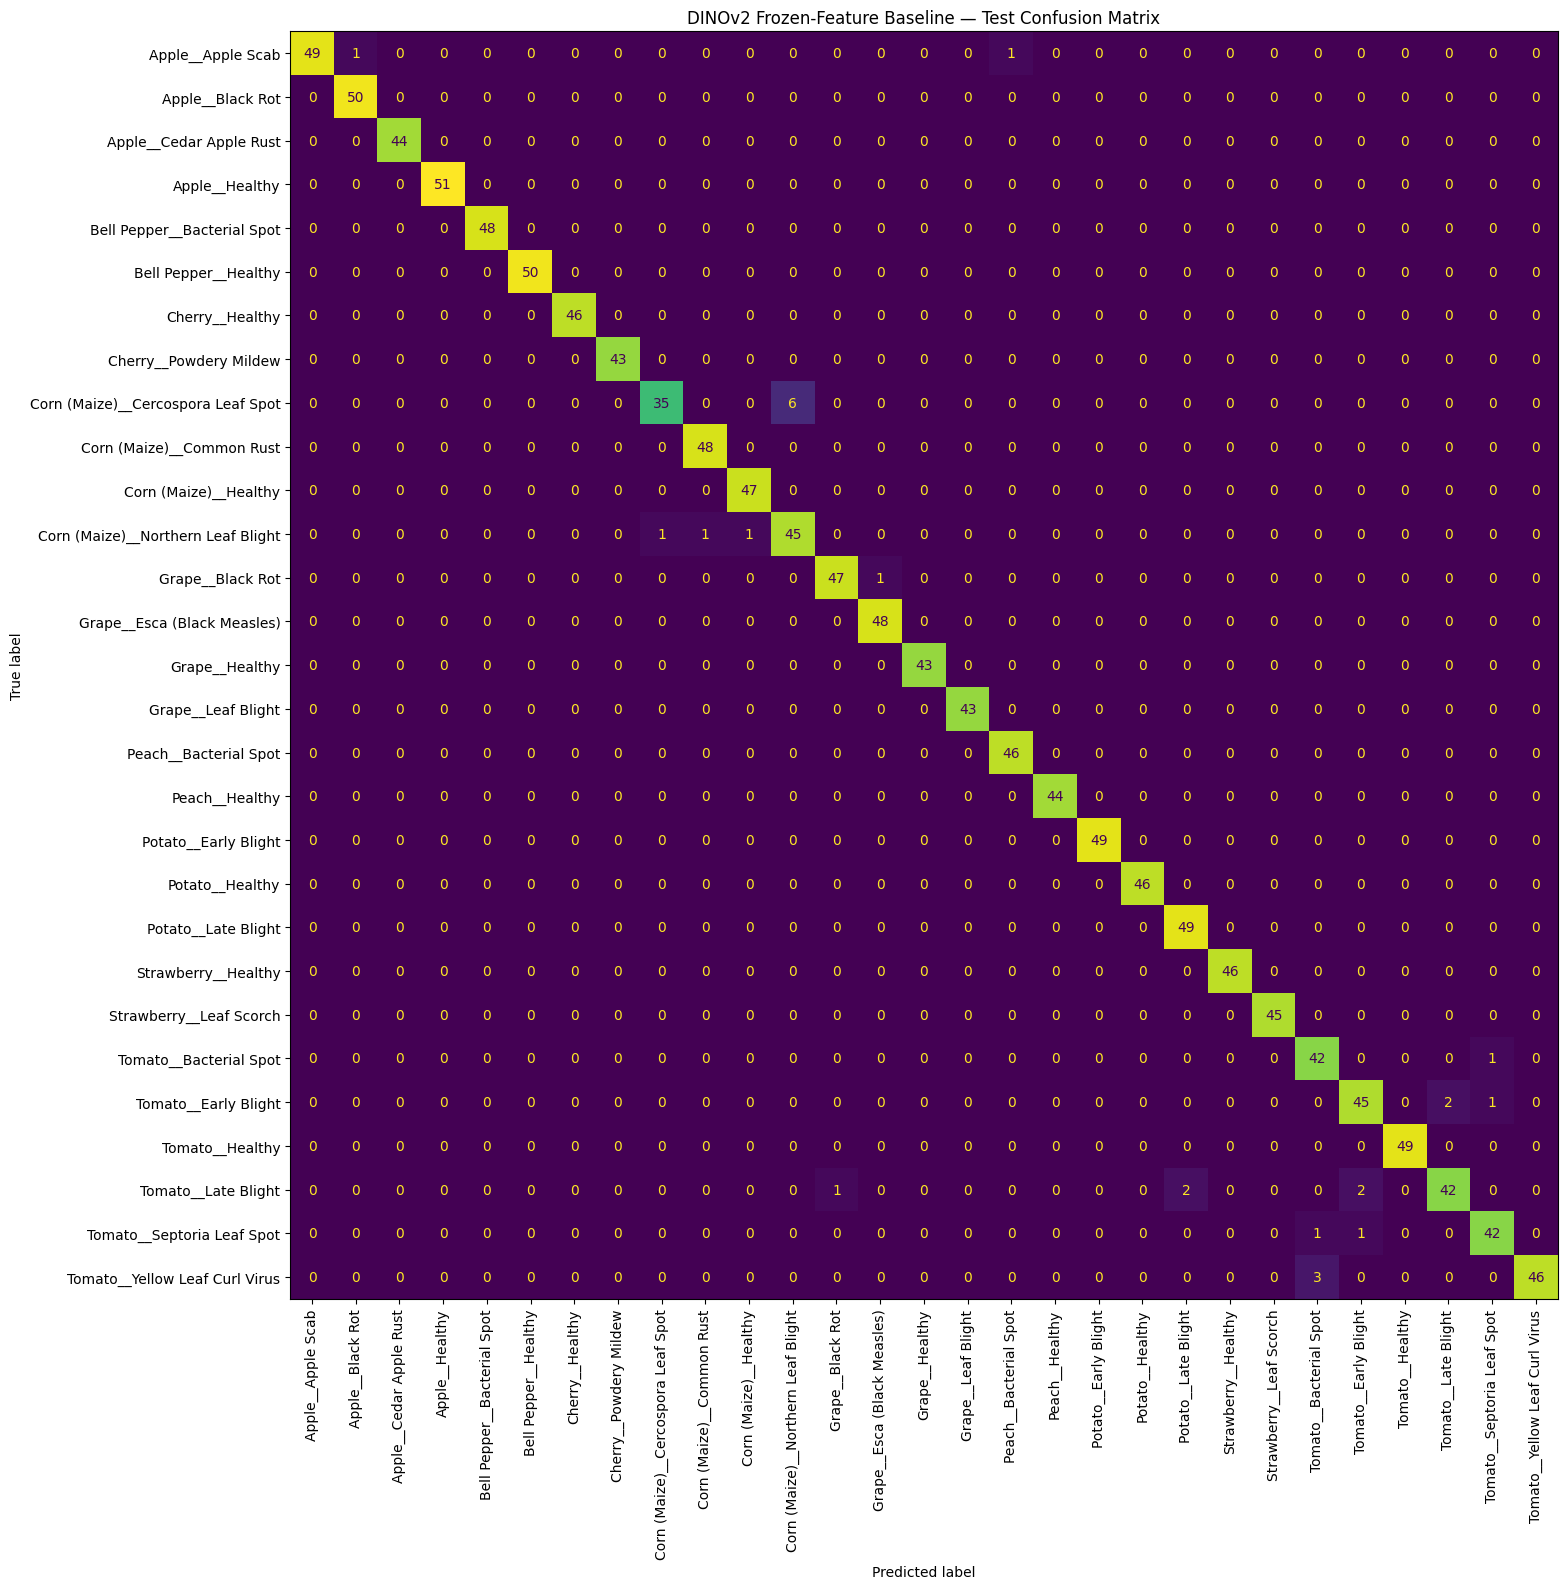


TOP MISCLASSIFICATION PAIRS


,true_class,predicted_class,count
0,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,6
1,Tomato__Yellow Leaf Curl Virus,Tomato__Bacterial Spot,3
2,Tomato__Early Blight,Tomato__Late Blight,2
3,Tomato__Late Blight,Tomato__Early Blight,2
4,Tomato__Late Blight,Potato__Late Blight,2
5,Apple__Apple Scab,Apple__Black Rot,1
6,Apple__Apple Scab,Peach__Bacterial Spot,1
7,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Cercospora Leaf Spot,1
8,Tomato__Bacterial Spot,Tomato__Septoria Leaf Spot,1
9,Grape__Black Rot,Grape__Esca (Black Measles),1



✓ PER-CLASS ANALYSIS COMPLETED
Classes evaluated : 29
Total test errors : 26
Lowest class F1   : 0.9091
Highest class F1  : 1.0000


In [ ]:
# ============================================================
# CELL-13 — DINOv2 Per-Class Performance + Confusion Matrix
#            Final corrected version
# ============================================================

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# Load class mapping
# ------------------------------------------------------------

CLASS_MAPPING_PATH = "/content/dinov2_manifest/class_mapping.json"

with open(CLASS_MAPPING_PATH, "r") as f:
    mapping_data = json.load(f)

# The JSON contains:
# {
#     "class_to_idx": {...},
#     "idx_to_class": {...}
# }

idx_to_class = mapping_data["idx_to_class"]

# Build ordered class list
class_names = [
    idx_to_class[str(i)]
    for i in range(NUM_CLASSES)
]

assert len(class_names) == NUM_CLASSES

print(f"Loaded {len(class_names)} classes successfully.")

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

report = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

per_class_df = pd.DataFrame(report).T

per_class_df = per_class_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
]

# Lowest-performing classes first
per_class_df = per_class_df.sort_values(
    "f1-score"
)

print("\n" + "=" * 90)
print("DINOV2 PER-CLASS TEST PERFORMANCE")
print("=" * 90)

display(
    per_class_df.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    })
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES)
)

print("\n" + "=" * 90)
print("CONFUSION MATRIX")
print("=" * 90)

fig, ax = plt.subplots(
    figsize=(18, 16)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "DINOv2 Frozen-Feature Baseline — Test Confusion Matrix"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Extract actual misclassification pairs
# ------------------------------------------------------------

confusions = []

for true_idx in range(NUM_CLASSES):

    for pred_idx in range(NUM_CLASSES):

        if (
            true_idx != pred_idx
            and cm[true_idx, pred_idx] > 0
        ):

            confusions.append({
                "true_class": class_names[true_idx],
                "predicted_class": class_names[pred_idx],
                "count": int(cm[true_idx, pred_idx])
            })

if confusions:

    confusion_df = pd.DataFrame(
        confusions
    ).sort_values(
        "count",
        ascending=False
    ).reset_index(drop=True)

    print("\n" + "=" * 90)
    print("TOP MISCLASSIFICATION PAIRS")
    print("=" * 90)

    display(confusion_df)

else:

    print("\nNo misclassifications found.")

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("✓ PER-CLASS ANALYSIS COMPLETED")
print("=" * 90)

print(f"Classes evaluated : {NUM_CLASSES}")

print(
    f"Total test errors : "
    f"{np.sum(all_labels != all_predictions)}"
)

print(
    f"Lowest class F1   : "
    f"{per_class_df['f1-score'].min():.4f}"
)

print(
    f"Highest class F1  : "
    f"{per_class_df['f1-score'].max():.4f}"
)

**Cell-14 — Confidence & Calibration Analysis**

DINOV2 CONFIDENCE ANALYSIS
Total predictions       : 1354
Correct predictions     : 1328
Incorrect predictions   : 26

Mean confidence        : 0.8607
Mean correct confidence: 0.8683
Mean incorrect confidence: 0.4716

Min correct confidence : 0.2676
Max incorrect confidence: 0.9248
Median correct confidence: 0.9053
Median incorrect confidence: 0.4319

HIGHEST-CONFIDENCE WRONG PREDICTIONS


,true_class,predicted_class,confidence
0,Tomato__Late Blight,Tomato__Early Blight,0.924805
1,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.771484
2,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Cercospora Leaf Spot,0.703613
3,Tomato__Septoria Leaf Spot,Tomato__Early Blight,0.685547
4,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Healthy,0.651855
5,Tomato__Yellow Leaf Curl Virus,Tomato__Bacterial Spot,0.644531
6,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Common Rust,0.622070
7,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.517578
8,Tomato__Yellow Leaf Curl Virus,Tomato__Bacterial Spot,0.496582
9,Tomato__Early Blight,Tomato__Late Blight,0.493408



CALIBRATION RESULTS
ECE         : 0.1201
Brier score : 0.0515

CALIBRATION BINS


,bin_lower,bin_upper,count,accuracy,confidence
0,0.2,0.3,6,0.3333,0.2711
1,0.3,0.4,15,0.5333,0.3557
2,0.4,0.5,24,0.7083,0.4538
3,0.5,0.6,33,0.9697,0.5437
4,0.6,0.7,65,0.9385,0.6597
5,0.7,0.8,120,0.9833,0.7588
6,0.8,0.9,392,1.0000,0.8597
7,0.9,1.0,699,0.9986,0.9422


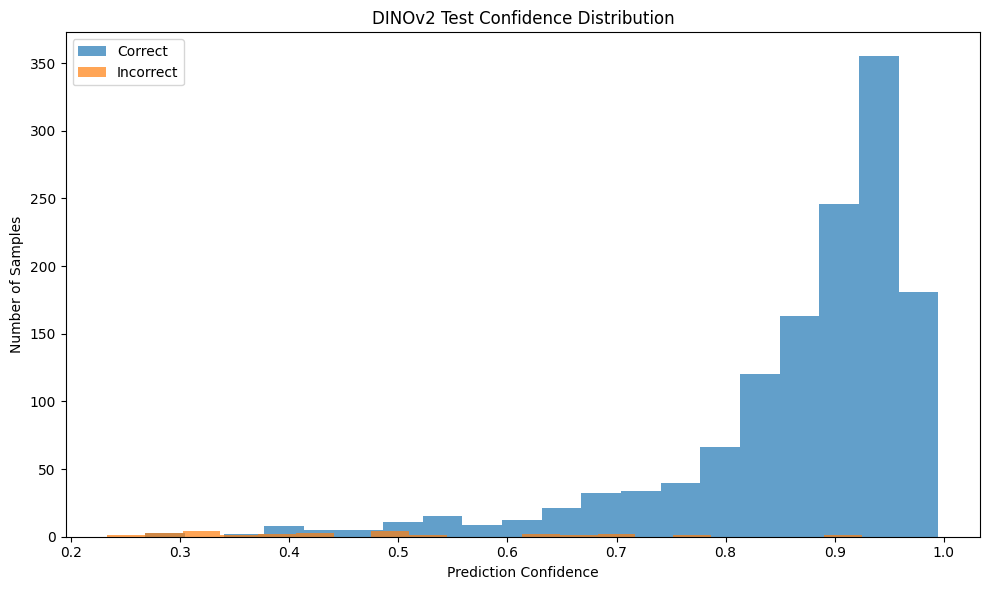


✓ CONFIDENCE & CALIBRATION ANALYSIS COMPLETED


In [ ]:
# ============================================================
# CELL-14 — DINOv2 Confidence & Calibration Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Correctness mask
# ------------------------------------------------------------

correct_mask = (
    all_labels == all_predictions
)

incorrect_mask = ~correct_mask

correct_confidences = all_confidences[
    correct_mask
]

incorrect_confidences = all_confidences[
    incorrect_mask
]

# ------------------------------------------------------------
# Basic confidence statistics
# ------------------------------------------------------------

print("=" * 80)
print("DINOV2 CONFIDENCE ANALYSIS")
print("=" * 80)

print(f"Total predictions       : {len(all_labels)}")
print(f"Correct predictions     : {correct_mask.sum()}")
print(f"Incorrect predictions   : {incorrect_mask.sum()}")

print(
    f"\nMean confidence        : "
    f"{all_confidences.mean():.4f}"
)

print(
    f"Mean correct confidence: "
    f"{correct_confidences.mean():.4f}"
)

print(
    f"Mean incorrect confidence: "
    f"{incorrect_confidences.mean():.4f}"
)

print(
    f"\nMin correct confidence : "
    f"{correct_confidences.min():.4f}"
)

print(
    f"Max incorrect confidence: "
    f"{incorrect_confidences.max():.4f}"
)

print(
    f"Median correct confidence: "
    f"{np.median(correct_confidences):.4f}"
)

print(
    f"Median incorrect confidence: "
    f"{np.median(incorrect_confidences):.4f}"
)

# ------------------------------------------------------------
# Identify highest-confidence errors
# ------------------------------------------------------------

error_indices = np.where(
    incorrect_mask
)[0]

error_table = pd.DataFrame({
    "true_class": [
        class_names[i]
        for i in all_labels[error_indices]
    ],
    "predicted_class": [
        class_names[i]
        for i in all_predictions[error_indices]
    ],
    "confidence": all_confidences[error_indices]
})

error_table = error_table.sort_values(
    "confidence",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 80)
print("HIGHEST-CONFIDENCE WRONG PREDICTIONS")
print("=" * 80)

display(
    error_table
)

# ------------------------------------------------------------
# Expected Calibration Error
# ------------------------------------------------------------

def calculate_ece(
    confidences,
    predictions,
    labels,
    n_bins=10
):

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    rows = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:

            mask = (
                (confidences >= lower) &
                (confidences <= upper)
            )

        else:

            mask = (
                (confidences >= lower) &
                (confidences < upper)
            )

        count = mask.sum()

        if count == 0:
            continue

        accuracy_bin = (
            predictions[mask] ==
            labels[mask]
        ).mean()

        confidence_bin = (
            confidences[mask].mean()
        )

        fraction = count / len(labels)

        ece += (
            fraction *
            abs(accuracy_bin - confidence_bin)
        )

        rows.append({
            "bin_lower": lower,
            "bin_upper": upper,
            "count": count,
            "accuracy": accuracy_bin,
            "confidence": confidence_bin
        })

    return ece, pd.DataFrame(rows)


ece, calibration_df = calculate_ece(
    all_confidences,
    all_predictions,
    all_labels,
    n_bins=10
)

# ------------------------------------------------------------
# Brier score
# ------------------------------------------------------------

# For multiclass classification:
# Brier = mean(sum((p_k - y_k)^2))

# Reconstruct one-hot labels from predictions is NOT valid,
# so obtain probabilities again from the test set.

all_probabilities = []

classifier.eval()
model.eval()

with torch.inference_mode():

    for batch_data in test_loader:

        pixel_values = batch_data["pixel_values"].to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            features = extract_features(
                pixel_values
            )

            logits = classifier(
                features
            )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        all_probabilities.append(
            probabilities.float().cpu().numpy()
        )

all_probabilities = np.concatenate(
    all_probabilities,
    axis=0
)

one_hot = np.zeros_like(
    all_probabilities
)

one_hot[
    np.arange(len(all_labels)),
    all_labels
] = 1.0

brier_score = np.mean(
    np.sum(
        (all_probabilities - one_hot) ** 2,
        axis=1
    )
)

# ------------------------------------------------------------
# Print calibration results
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CALIBRATION RESULTS")
print("=" * 80)

print(f"ECE         : {ece:.4f}")
print(f"Brier score : {brier_score:.4f}")

# ------------------------------------------------------------
# Calibration table
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CALIBRATION BINS")
print("=" * 80)

display(
    calibration_df.style.format({
        "bin_lower": "{:.1f}",
        "bin_upper": "{:.1f}",
        "count": "{:.0f}",
        "accuracy": "{:.4f}",
        "confidence": "{:.4f}"
    })
)

# ------------------------------------------------------------
# Confidence distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    correct_confidences,
    bins=20,
    alpha=0.7,
    label="Correct"
)

plt.hist(
    incorrect_confidences,
    bins=20,
    alpha=0.7,
    label="Incorrect"
)

plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Samples")
plt.title(
    "DINOv2 Test Confidence Distribution"
)

plt.legend()
plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("✓ CONFIDENCE & CALIBRATION ANALYSIS COMPLETED")
print("=" * 80)

**CELL-15 — Validation-Based Abstention Threshold**

In [ ]:
# ============================================================
# CELL-15 — Validation-Based Abstention Threshold
# ============================================================

import numpy as np
import pandas as pd
import torch
from tqdm import tqdm

# ------------------------------------------------------------
# Helper: collect probabilities from a dataloader
# ------------------------------------------------------------

def collect_predictions(dataloader):

    predictions = []
    labels = []
    confidences = []

    classifier.eval()
    model.eval()

    with torch.inference_mode():

        for batch_data in tqdm(
            dataloader,
            desc="Collecting predictions",
            unit="batch"
        ):

            pixel_values = batch_data["pixel_values"].to(
                device,
                non_blocking=True
            )

            batch_labels = batch_data["labels"].to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                features = extract_features(
                    pixel_values
                )

                logits = classifier(
                    features
                )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            batch_confidences, batch_predictions = (
                torch.max(
                    probabilities,
                    dim=1
                )
            )

            predictions.extend(
                batch_predictions.cpu().numpy()
            )

            labels.extend(
                batch_labels.cpu().numpy()
            )

            confidences.extend(
                batch_confidences.float().cpu().numpy()
            )

    return (
        np.array(labels),
        np.array(predictions),
        np.array(confidences)
    )


# ------------------------------------------------------------
# Collect VALIDATION predictions
# ------------------------------------------------------------

print("=" * 80)
print("VALIDATION CONFIDENCE ANALYSIS")
print("=" * 80)

val_labels, val_predictions, val_confidences = (
    collect_predictions(val_loader)
)

val_correct = (
    val_labels == val_predictions
)

val_errors = ~val_correct

print(
    f"\nValidation samples : {len(val_labels)}"
)

print(
    f"Validation correct : {val_correct.sum()}"
)

print(
    f"Validation errors  : {val_errors.sum()}"
)

print(
    f"Validation accuracy: "
    f"{val_correct.mean():.4f}"
)

# ------------------------------------------------------------
# Find lowest threshold with zero observed validation risk
# ------------------------------------------------------------

wrong_confidences = val_confidences[
    val_errors
]

if len(wrong_confidences) == 0:

    threshold = 0.0

else:

    threshold = (
        wrong_confidences.max()
        + 1e-6
    )

# ------------------------------------------------------------
# Validation selective performance
# ------------------------------------------------------------

val_accept = (
    val_confidences >= threshold
)

val_abstain = ~val_accept

val_accepted = val_accept.sum()

val_abstained = val_abstain.sum()

if val_accepted > 0:

    val_selective_accuracy = (
        val_correct[val_accept].mean()
    )

    val_selective_risk = (
        1.0 - val_selective_accuracy
    )

else:

    val_selective_accuracy = np.nan
    val_selective_risk = np.nan

val_coverage = (
    val_accepted / len(val_labels)
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("VALIDATION-BASED ABSTENTION THRESHOLD")
print("=" * 80)

print(
    f"Threshold                  : "
    f"{threshold:.6f}"
)

print(
    f"Accepted                   : "
    f"{val_accepted}"
)

print(
    f"Abstained                  : "
    f"{val_abstained}"
)

print(
    f"Coverage                   : "
    f"{val_coverage:.4f}"
)

print(
    f"Selective accuracy         : "
    f"{val_selective_accuracy:.4f}"
)

print(
    f"Selective risk              : "
    f"{val_selective_risk:.4f}"
)

print(
    "\nNOTE: This threshold is derived ONLY "
    "from the validation set."
)

print(
    "Zero observed validation risk "
    "is not a statistical guarantee."
)

print("\n" + "=" * 80)
print("✓ VALIDATION THRESHOLD SELECTED")
print("=" * 80)

VALIDATION CONFIDENCE ANALYSIS



Validation samples : 12067
Validation correct : 11940
Validation errors  : 127
Validation accuracy: 0.9895

VALIDATION-BASED ABSTENTION THRESHOLD
Threshold                  : 0.962892
Accepted                   : 1198
Abstained                  : 10869
Coverage                   : 0.0993
Selective accuracy         : 1.0000
Selective risk              : 0.0000

NOTE: This threshold is derived ONLY from the validation set.
Zero observed validation risk is not a statistical guarantee.

✓ VALIDATION THRESHOLD SELECTED


**Cell-16 — Apply frozen threshold to Test**

In [ ]:
# ============================================================
# CELL-16 — Test-Time Abstention Using Frozen Validation Threshold
# ============================================================

import numpy as np
import torch
from tqdm import tqdm

print("=" * 80)
print("TEST-TIME ABSTENTION EVALUATION")
print("=" * 80)

# ------------------------------------------------------------
# Frozen threshold selected ONLY from validation set
# ------------------------------------------------------------
TEST_THRESHOLD = threshold

test_labels, test_predictions, test_confidences = collect_predictions(test_loader)

test_correct = test_labels == test_predictions
test_errors = ~test_correct

# ------------------------------------------------------------
# Apply frozen threshold
# ------------------------------------------------------------
test_accept = test_confidences >= TEST_THRESHOLD
test_abstain = ~test_accept

accepted = test_accept.sum()
abstained = test_abstain.sum()
total = len(test_labels)

coverage = accepted / total
abstention_rate = abstained / total

# ------------------------------------------------------------
# Selective performance
# ------------------------------------------------------------
if accepted > 0:
    selective_accuracy = test_correct[test_accept].mean()
    selective_risk = 1.0 - selective_accuracy
else:
    selective_accuracy = np.nan
    selective_risk = np.nan

# Ordinary test performance
ordinary_accuracy = test_correct.mean()

# ------------------------------------------------------------
# Error analysis
# ------------------------------------------------------------
accepted_errors = (~test_correct[test_accept]).sum()
abstained_correct = test_correct[test_abstain].sum()
abstained_errors = (~test_correct[test_abstain]).sum()

print("\n" + "=" * 80)
print("FROZEN VALIDATION THRESHOLD")
print("=" * 80)

print(f"Threshold                  : {TEST_THRESHOLD:.6f}")

print("\n" + "=" * 80)
print("TEST SET")
print("=" * 80)

print(f"Total test samples        : {total}")
print(f"Ordinary test accuracy    : {ordinary_accuracy:.4f}")

print("\n" + "=" * 80)
print("ABSTENTION RESULTS")
print("=" * 80)

print(f"Accepted                   : {accepted}")
print(f"Abstained                  : {abstained}")
print(f"Coverage                   : {coverage:.4f}")
print(f"Abstention rate            : {abstention_rate:.4f}")
print(f"Selective accuracy         : {selective_accuracy:.4f}")
print(f"Selective risk              : {selective_risk:.4f}")

print("\n" + "=" * 80)
print("ERROR DISTRIBUTION")
print("=" * 80)

print(f"Errors among accepted      : {accepted_errors}")
print(f"Correct among abstained    : {abstained_correct}")
print(f"Errors among abstained     : {abstained_errors}")

print("\n" + "=" * 80)
print("✓ TEST ABSTENTION EVALUATION COMPLETE")
print("=" * 80)

print("\nIMPORTANT:")
print("The threshold was selected exclusively from validation data")
print("and was NOT adjusted using test results.")

TEST-TIME ABSTENTION EVALUATION



FROZEN VALIDATION THRESHOLD
Threshold                  : 0.962892

TEST SET
Total test samples        : 1354
Ordinary test accuracy    : 0.9808

ABSTENTION RESULTS
Accepted                   : 148
Abstained                  : 1206
Coverage                   : 0.1093
Abstention rate            : 0.8907
Selective accuracy         : 1.0000
Selective risk              : 0.0000

ERROR DISTRIBUTION
Errors among accepted      : 0
Correct among abstained    : 1180
Errors among abstained     : 26

✓ TEST ABSTENTION EVALUATION COMPLETE

IMPORTANT:
The threshold was selected exclusively from validation data
and was NOT adjusted using test results.


**CELL-17 — DINOv2 Risk-Coverage Curve and AURC**

In [ ]:
# ============================================================
# CELL-17 — DINOv2 Risk-Coverage Curve and AURC
# ============================================================

import numpy as np
import pandas as pd

print("=" * 80)
print("DINOv2 RISK-COVERAGE ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# Use TEST predictions collected in Cell-16
# ------------------------------------------------------------
correct = test_correct.astype(np.float64)

# Sort predictions by confidence, highest confidence first
order = np.argsort(-test_confidences)

sorted_correct = correct[order]
sorted_confidences = test_confidences[order]

# ------------------------------------------------------------
# Progressive acceptance
# ------------------------------------------------------------
cumulative_errors = np.cumsum(1.0 - sorted_correct)
sample_counts = np.arange(1, len(sorted_correct) + 1)

coverage_curve = sample_counts / len(sorted_correct)
risk_curve = cumulative_errors / sample_counts

# ------------------------------------------------------------
# AURC using trapezoidal integration
# ------------------------------------------------------------
aurc = np.trapezoid(risk_curve, coverage_curve)

print(f"\nTotal test samples : {len(test_labels)}")
print(f"AURC                : {aurc:.6f}")

# ------------------------------------------------------------
# Risk at selected coverage levels
# ------------------------------------------------------------
coverage_points = [0.10, 0.20, 0.30, 0.40, 0.50,
                   0.60, 0.70, 0.80, 0.90, 1.00]

rows = []

for target_coverage in coverage_points:
    k = max(1, int(np.ceil(target_coverage * len(sorted_correct))))

    accepted_correct = sorted_correct[:k].sum()
    accepted_errors = k - accepted_correct

    actual_coverage = k / len(sorted_correct)
    risk = accepted_errors / k

    rows.append({
        "Target Coverage": target_coverage,
        "Actual Coverage": actual_coverage,
        "Accepted": k,
        "Errors": int(accepted_errors),
        "Risk": risk
    })

risk_df = pd.DataFrame(rows)

print("\n" + "=" * 80)
print("RISK AT SELECTED COVERAGE LEVELS")
print("=" * 80)

print(risk_df.to_string(index=False))

# ------------------------------------------------------------
# Risk at the actual validation-derived threshold
# ------------------------------------------------------------
threshold_mask = test_confidences >= TEST_THRESHOLD

threshold_coverage = threshold_mask.mean()
threshold_errors = (~test_correct & threshold_mask).sum()
threshold_accepted = threshold_mask.sum()
threshold_risk = (
    threshold_errors / threshold_accepted
    if threshold_accepted > 0 else np.nan
)

print("\n" + "=" * 80)
print("VALIDATION-DERIVED THRESHOLD ON TEST")
print("=" * 80)

print(f"Threshold : {TEST_THRESHOLD:.6f}")
print(f"Coverage  : {threshold_coverage:.4f}")
print(f"Accepted  : {threshold_accepted}")
print(f"Errors    : {threshold_errors}")
print(f"Risk      : {threshold_risk:.4f}")

print("\n" + "=" * 80)
print("✓ RISK-COVERAGE ANALYSIS COMPLETE")
print("=" * 80)

DINOv2 RISK-COVERAGE ANALYSIS

Total test samples : 1354
AURC                : 0.001387

RISK AT SELECTED COVERAGE LEVELS
 Target Coverage  Actual Coverage  Accepted  Errors     Risk
             0.1         0.100443       136       0 0.000000
             0.2         0.200148       271       0 0.000000
             0.3         0.300591       407       0 0.000000
             0.4         0.400295       542       1 0.001845
             0.5         0.500000       677       1 0.001477
             0.6         0.600443       813       1 0.001230
             0.7         0.700148       948       1 0.001055
             0.8         0.800591      1084       1 0.000923
             0.9         0.900295      1219       3 0.002461
             1.0         1.000000      1354      26 0.019202

VALIDATION-DERIVED THRESHOLD ON TEST
Threshold : 0.962892
Coverage  : 0.1093
Accepted  : 148
Errors    : 0
Risk      : 0.0000

✓ RISK-COVERAGE ANALYSIS COMPLETE


**CELL-18 — Save DINOv2 Experiment Summary**

In [ ]:
# ============================================================
# CELL-18 — Save DINOv2 Experiment Summary
# ============================================================

import os
import json
import torch

DINOV2_RESULTS_DIR = "/content/dinov2_results"
os.makedirs(DINOV2_RESULTS_DIR, exist_ok=True)

# ------------------------------------------------------------
# Core experiment summary
# ------------------------------------------------------------
dinov2_summary = {
    "model": "facebook/dinov2-small",

    "architecture": {
        "parameters_total": 22060000,
        "hidden_size": 384,
        "image_size_config": 518,
        "patch_size": 14,
        "hidden_layers": 12,
        "actual_input_size": 224
    },

    "dataset": {
        "num_classes": 29,
        "train_samples": 53690,
        "validation_samples": 12067,
        "test_samples": 1354
    },

    "training": {
        "strategy": "frozen_backbone_linear_classifier",
        "epochs": 5,
        "learning_rate": 0.001,
        "weight_decay": 0.0001,
        "label_smoothing": 0.1,
        "best_epoch": 4,
        "best_validation_accuracy": 0.9895
    },

    "test_classification": {
        "accuracy": 0.9808,
        "macro_precision": 0.9811,
        "macro_recall": 0.9804,
        "macro_f1": 0.9804,
        "weighted_precision": 0.9812,
        "weighted_recall": 0.9808,
        "weighted_f1": 0.9807,
        "correct": 1328,
        "incorrect": 26
    },

    "confidence": {
        "mean_confidence": 0.8607,
        "mean_correct_confidence": 0.8683,
        "mean_incorrect_confidence": 0.4716,
        "median_correct_confidence": 0.9053,
        "median_incorrect_confidence": 0.4319,
        "ece": 0.1201,
        "brier_score": 0.0515
    },

    "abstention": {
        "validation_threshold": 0.962892,
        "validation_coverage": 0.0993,
        "validation_selective_accuracy": 1.0,
        "validation_selective_risk": 0.0,

        "test_coverage": 0.1093,
        "test_abstention_rate": 0.8907,
        "test_accepted": 148,
        "test_abstained": 1206,
        "test_selective_accuracy": 1.0,
        "test_selective_risk": 0.0,
        "test_accepted_errors": 0,
        "test_abstained_errors": 26
    },

    "risk_coverage": {
        "test_aurc": 0.001387,

        "risk_at_10_percent": 0.000000,
        "risk_at_20_percent": 0.000000,
        "risk_at_30_percent": 0.000000,
        "risk_at_40_percent": 0.001845,
        "risk_at_50_percent": 0.001477,
        "risk_at_60_percent": 0.001230,
        "risk_at_70_percent": 0.001055,
        "risk_at_80_percent": 0.000923,
        "risk_at_90_percent": 0.002461,
        "risk_at_100_percent": 0.019202
    }
}

# ------------------------------------------------------------
# Save JSON
# ------------------------------------------------------------
summary_path = os.path.join(
    DINOV2_RESULTS_DIR,
    "dinov2_experiment_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(dinov2_summary, f, indent=4)

print("=" * 80)
print("DINOv2 EXPERIMENT SUMMARY SAVED")
print("=" * 80)

print(f"\nDirectory : {DINOV2_RESULTS_DIR}")
print(f"File      : {summary_path}")
print(f"Size      : {os.path.getsize(summary_path) / 1024:.2f} KB")

print("\n" + "=" * 80)
print("KEY RESULTS")
print("=" * 80)

print(f"Test accuracy       : {dinov2_summary['test_classification']['accuracy']:.4f}")
print(f"Macro F1            : {dinov2_summary['test_classification']['macro_f1']:.4f}")
print(f"ECE                 : {dinov2_summary['confidence']['ece']:.4f}")
print(f"AURC                : {dinov2_summary['risk_coverage']['test_aurc']:.6f}")
print(f"Abstention threshold: {dinov2_summary['abstention']['validation_threshold']:.6f}")
print(f"Test coverage       : {dinov2_summary['abstention']['test_coverage']:.4f}")
print(f"Selective accuracy  : {dinov2_summary['abstention']['test_selective_accuracy']:.4f}")
print(f"Selective risk      : {dinov2_summary['abstention']['test_selective_risk']:.4f}")

print("\n✓ Reproducibility summary saved.")

DINOv2 EXPERIMENT SUMMARY SAVED

Directory : /content/dinov2_results
File      : /content/dinov2_results/dinov2_experiment_summary.json
Size      : 2.15 KB

KEY RESULTS
Test accuracy       : 0.9808
Macro F1            : 0.9804
ECE                 : 0.1201
AURC                : 0.001387
Abstention threshold: 0.962892
Test coverage       : 0.1093
Selective accuracy  : 1.0000
Selective risk      : 0.0000

✓ Reproducibility summary saved.


**Cell-19A — Inspect checkpoint keys**

In [ ]:
# ============================================================
# CELL-19A — Inspect DINOv2 Checkpoint Structure
# ============================================================

import torch

checkpoint = torch.load(
    "/content/dinov2_linear_best.pth",
    map_location="cpu"
)

print("=" * 80)
print("DINOV2 CHECKPOINT STRUCTURE")
print("=" * 80)

print(f"\nCheckpoint type: {type(checkpoint)}")

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        value = checkpoint[key]

        if isinstance(value, dict):
            print(f"  {key:<30} -> dict ({len(value)} entries)")
        elif torch.is_tensor(value):
            print(f"  {key:<30} -> tensor {tuple(value.shape)}")
        else:
            print(f"  {key:<30} -> {type(value).__name__}: {value}")
else:
    print("\nCheckpoint is not a dictionary.")

print("\n" + "=" * 80)
print("✓ CHECKPOINT INSPECTION COMPLETE")
print("=" * 80)

DINOV2 CHECKPOINT STRUCTURE

Checkpoint type: <class 'dict'>

Checkpoint keys:
  model_state_dict               -> dict (2 entries)
  best_val_accuracy              -> float: 0.9894754288555565
  epoch                          -> int: 4
  feature_dim                    -> int: 384
  num_classes                    -> int: 29
  model_id                       -> str: facebook/dinov2-small
  learning_rate                  -> float: 0.001
  weight_decay                   -> float: 0.0001
  label_smoothing                -> float: 0.1

✓ CHECKPOINT INSPECTION COMPLETE


**Cell-19B — Inspect actual model parameter structure**

In [ ]:
# ============================================================
# CELL-19B — Inspect DINOv2 Model Parameter Structure
# ============================================================

import torch

print("=" * 80)
print("DINOV2 MODEL PARAMETER STRUCTURE")
print("=" * 80)

# ------------------------------------------------------------
# Restore frozen-classifier checkpoint
# ------------------------------------------------------------
checkpoint = torch.load(
    "/content/dinov2_linear_best.pth",
    map_location=device
)

model_state = checkpoint["model_state_dict"]

print("\nCheckpoint model_state_dict keys:")
for key in model_state.keys():
    print(f"  {key}")

# ------------------------------------------------------------
# Inspect DINOv2 parameter names
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("DINOv2 PARAMETER NAMES")
print("=" * 80)

all_names = list(model.named_parameters())

print(f"\nTotal parameter tensors: {len(all_names)}")

for i, (name, param) in enumerate(all_names):
    print(f"{i:3d} | {name:<70} | {tuple(param.shape)}")

print("\n" + "=" * 80)
print("MODEL MODULE HIERARCHY")
print("=" * 80)

for name, module in model.named_children():
    print(f"{name:<30} -> {module.__class__.__name__}")

print("\n" + "=" * 80)
print("✓ MODEL STRUCTURE INSPECTION COMPLETE")
print("=" * 80)

DINOV2 MODEL PARAMETER STRUCTURE

Checkpoint model_state_dict keys:
  weight
  bias

DINOv2 PARAMETER NAMES

Total parameter tensors: 223
  0 | embeddings.cls_token                                                   | (1, 1, 384)
  1 | embeddings.mask_token                                                  | (1, 384)
  2 | embeddings.position_embeddings                                         | (1, 1370, 384)
  3 | embeddings.patch_embeddings.projection.weight                          | (384, 3, 14, 14)
  4 | embeddings.patch_embeddings.projection.bias                            | (384,)
  5 | encoder.layer.0.norm1.weight                                           | (384,)
  6 | encoder.layer.0.norm1.bias                                             | (384,)
  7 | encoder.layer.0.attention.attention.query.weight                       | (384, 384)
  8 | encoder.layer.0.attention.attention.query.bias                         | (384,)
  9 | encoder.layer.0.attention.attention.key.weight       

**Cell-19C — Correct controlled fine-tuning setup**

In [ ]:
# ============================================================
# CELL-19C — DINOv2 Controlled Fine-Tuning Setup
# ============================================================

import torch
import torch.nn as nn

print("=" * 80)
print("DINOv2 CONTROLLED FINE-TUNING SETUP")
print("=" * 80)

# ------------------------------------------------------------
# Restore best frozen-classifier checkpoint
# ------------------------------------------------------------
checkpoint = torch.load(
    "/content/dinov2_linear_best.pth",
    map_location=device
)

classifier.load_state_dict(checkpoint["model_state_dict"])

print("\n✓ Best classifier checkpoint restored")
print(f"  Best validation accuracy: {checkpoint['best_val_accuracy']:.4f}")
print(f"  Best epoch               : {checkpoint['epoch']}")

# ------------------------------------------------------------
# Freeze entire DINOv2 backbone
# ------------------------------------------------------------
for param in model.parameters():
    param.requires_grad = False

# ------------------------------------------------------------
# Unfreeze ONLY final transformer block
# ------------------------------------------------------------
final_block = model.encoder.layer[-1]

for param in final_block.parameters():
    param.requires_grad = True

# Classifier remains trainable
for param in classifier.parameters():
    param.requires_grad = True

# ------------------------------------------------------------
# Parameter accounting
# ------------------------------------------------------------
total_backbone_params = sum(
    p.numel() for p in model.parameters()
)

trainable_backbone_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

classifier_params = sum(
    p.numel()
    for p in classifier.parameters()
)

trainable_total = trainable_backbone_params + classifier_params

all_total = total_backbone_params + classifier_params

print("\n" + "=" * 80)
print("PARAMETER SUMMARY")
print("=" * 80)

print(f"Total DINOv2 backbone : {total_backbone_params:,}")
print(f"Trainable final block : {trainable_backbone_params:,}")
print(f"Classifier parameters : {classifier_params:,}")
print(f"Total trainable       : {trainable_total:,}")
print(f"Trainable percentage   : {100 * trainable_total / all_total:.2f}%")

# ------------------------------------------------------------
# Verify frozen vs trainable blocks
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("TRANSFORMER BLOCK STATUS")
print("=" * 80)

for i, block in enumerate(model.encoder.layer):
    block_trainable = any(
        p.requires_grad for p in block.parameters()
    )

    status = "TRAINABLE" if block_trainable else "FROZEN"

    print(f"Block {i:02d} : {status}")

# ------------------------------------------------------------
# Verify final LayerNorm remains frozen
# ------------------------------------------------------------
layernorm_trainable = any(
    p.requires_grad for p in model.layernorm.parameters()
)

print(
    f"\nFinal LayerNorm : "
    f"{'TRAINABLE' if layernorm_trainable else 'FROZEN'}"
)

# ------------------------------------------------------------
# Verify classifier
# ------------------------------------------------------------
classifier_trainable = all(
    p.requires_grad for p in classifier.parameters()
)

print(
    f"Classifier      : "
    f"{'TRAINABLE' if classifier_trainable else 'FROZEN'}"
)

# ------------------------------------------------------------
# Safety assertions
# ------------------------------------------------------------
assert all(
    not p.requires_grad
    for i, block in enumerate(model.encoder.layer[:-1])
    for p in block.parameters()
)

assert all(
    p.requires_grad
    for p in model.encoder.layer[-1].parameters()
)

assert not layernorm_trainable
assert classifier_trainable

print("\n" + "=" * 80)
print("✓ CONTROLLED FINE-TUNING CONFIGURATION VERIFIED")
print("=" * 80)

DINOv2 CONTROLLED FINE-TUNING SETUP

✓ Best classifier checkpoint restored
  Best validation accuracy: 0.9895
  Best epoch               : 4

PARAMETER SUMMARY
Total DINOv2 backbone : 22,056,576
Trainable final block : 1,775,232
Classifier parameters : 11,165
Total trainable       : 1,786,397
Trainable percentage   : 8.10%

TRANSFORMER BLOCK STATUS
Block 00 : FROZEN
Block 01 : FROZEN
Block 02 : FROZEN
Block 03 : FROZEN
Block 04 : FROZEN
Block 05 : FROZEN
Block 06 : FROZEN
Block 07 : FROZEN
Block 08 : FROZEN
Block 09 : FROZEN
Block 10 : FROZEN
Block 11 : TRAINABLE

Final LayerNorm : FROZEN
Classifier      : TRAINABLE

✓ CONTROLLED FINE-TUNING CONFIGURATION VERIFIED


**Cell-20 — Configure fine-tuning optimizer and verify**

In [ ]:
# ============================================================
# CELL-20 — DINOv2 Fine-Tuning Optimizer Configuration
# ============================================================

import torch

# ------------------------------------------------------------
# Learning rates
# ------------------------------------------------------------
BACKBONE_LR = 1e-5
CLASSIFIER_LR = 5e-4
WEIGHT_DECAY = 1e-4

# ------------------------------------------------------------
# Separate parameter groups
# ------------------------------------------------------------
backbone_params = [
    p for p in model.parameters()
    if p.requires_grad
]

classifier_params = [
    p for p in classifier.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    [
        {
            "params": backbone_params,
            "lr": BACKBONE_LR
        },
        {
            "params": classifier_params,
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------
NUM_FINE_TUNE_EPOCHS = 5

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_FINE_TUNE_EPOCHS
)

# ------------------------------------------------------------
# Configuration verification
# ------------------------------------------------------------
print("=" * 80)
print("DINOv2 FINE-TUNING OPTIMIZER")
print("=" * 80)

print(f"\nBackbone learning rate : {BACKBONE_LR}")
print(f"Classifier learning rate: {CLASSIFIER_LR}")
print(f"Weight decay           : {WEIGHT_DECAY}")
print(f"Fine-tuning epochs     : {NUM_FINE_TUNE_EPOCHS}")
print("Optimizer              : AdamW")
print("Scheduler              : CosineAnnealingLR")

print("\n" + "=" * 80)
print("PARAMETER GROUPS")
print("=" * 80)

for i, group in enumerate(optimizer.param_groups):
    param_count = sum(p.numel() for p in group["params"])

    print(
        f"Group {i}: "
        f"parameters={param_count:,}, "
        f"learning_rate={group['lr']}"
    )

print("\n" + "=" * 80)
print("✓ FINE-TUNING OPTIMIZER READY")
print("=" * 80)

DINOv2 FINE-TUNING OPTIMIZER

Backbone learning rate : 1e-05
Classifier learning rate: 0.0005
Weight decay           : 0.0001
Fine-tuning epochs     : 5
Optimizer              : AdamW
Scheduler              : CosineAnnealingLR

PARAMETER GROUPS
Group 0: parameters=1,775,232, learning_rate=1e-05
Group 1: parameters=11,165, learning_rate=0.0005

✓ FINE-TUNING OPTIMIZER READY


**Cell-21 — Train DINOv2 final block + classifier**

In [ ]:
# ============================================================
# CELL-21 — DINOv2 Controlled Fine-Tuning
# ============================================================

import os
import torch
import torch.nn as nn
from tqdm import tqdm

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
NUM_EPOCHS = NUM_FINE_TUNE_EPOCHS
LABEL_SMOOTHING = 0.1

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

best_val_accuracy_ft = -1.0
best_epoch_ft = -1

best_checkpoint_path = "/content/dinov2_finetuned_best.pth"

history_ft = []

print("=" * 80)
print("DINOv2 CONTROLLED FINE-TUNING")
print("=" * 80)

print(f"\nEpochs              : {NUM_EPOCHS}")
print(f"Backbone LR         : {BACKBONE_LR}")
print(f"Classifier LR       : {CLASSIFIER_LR}")
print(f"Label smoothing     : {LABEL_SMOOTHING}")
print(f"Trainable parameters: {trainable_total:,}")

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------
for epoch in range(NUM_EPOCHS):

    model.train()
    classifier.train()

    running_loss = 0.0
    running_correct = 0
    running_total = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}",
        unit="batch"
    )

    for batch_data in progress_bar:

        pixel_values = batch_data["pixel_values"].to(
            device,
            non_blocking=True
        )

        labels = batch_data["labels"].to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            features = extract_features(pixel_values)

            logits = classifier(features)

            loss = criterion(logits, labels)

        loss.backward()

        optimizer.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------
        running_loss += loss.item() * labels.size(0)

        predictions = logits.argmax(dim=1)

        running_correct += (
            predictions == labels
        ).sum().item()

        running_total += labels.size(0)

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = running_loss / running_total
    train_accuracy = running_correct / running_total

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------
    model.eval()
    classifier.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for batch_data in tqdm(
            val_loader,
            desc="Validation",
            unit="batch"
        ):

            pixel_values = batch_data["pixel_values"].to(
                device,
                non_blocking=True
            )

            labels = batch_data["labels"].to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                features = extract_features(pixel_values)

                logits = classifier(features)

                loss = criterion(logits, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = logits.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_accuracy = val_correct / val_total

    # --------------------------------------------------------
    # Scheduler step
    # --------------------------------------------------------
    scheduler.step()

    current_backbone_lr = optimizer.param_groups[0]["lr"]
    current_classifier_lr = optimizer.param_groups[1]["lr"]

    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------
    epoch_record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "backbone_lr": current_backbone_lr,
        "classifier_lr": current_classifier_lr
    }

    history_ft.append(epoch_record)

    # --------------------------------------------------------
    # Best validation checkpoint
    # --------------------------------------------------------
    is_best = val_accuracy > best_val_accuracy_ft

    if is_best:

        best_val_accuracy_ft = val_accuracy
        best_epoch_ft = epoch + 1

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "classifier_state_dict": classifier.state_dict(),
                "best_val_accuracy": best_val_accuracy_ft,
                "epoch": best_epoch_ft,
                "backbone_lr": BACKBONE_LR,
                "classifier_lr": CLASSIFIER_LR,
                "weight_decay": WEIGHT_DECAY,
                "label_smoothing": LABEL_SMOOTHING,
                "model_id": "facebook/dinov2-small",
                "feature_dim": FEATURE_DIM,
                "num_classes": NUM_CLASSES
            },
            best_checkpoint_path
        )

    # --------------------------------------------------------
    # Epoch summary
    # --------------------------------------------------------
    print("\n" + "-" * 80)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

    print(
        f"LR -> Backbone: {current_backbone_lr:.2e} | "
        f"Classifier: {current_classifier_lr:.2e}"
    )

    if is_best:
        print("★ NEW BEST VALIDATION CHECKPOINT")

    print("-" * 80)

# ------------------------------------------------------------
# Restore best checkpoint
# ------------------------------------------------------------
best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

classifier.load_state_dict(
    best_checkpoint["classifier_state_dict"]
)

model.eval()
classifier.eval()

print("\n" + "=" * 80)
print("✓ CONTROLLED FINE-TUNING COMPLETE")
print("=" * 80)

print(f"\nBest validation accuracy : {best_val_accuracy_ft:.4f}")
print(f"Best epoch              : {best_epoch_ft}")
print(f"Checkpoint              : {best_checkpoint_path}")

DINOv2 CONTROLLED FINE-TUNING

Epochs              : 5
Backbone LR         : 1e-05
Classifier LR       : 0.0005
Label smoothing     : 0.1
Trainable parameters: 1,786,397


Validation: 100%|██████████| 378/378 [00:43<00:00,  8.63batch/s]



--------------------------------------------------------------------------------
Epoch 1/5 | Train Loss: 0.7432 | Train Acc: 0.9918 | Val Loss: 0.7575 | Val Acc: 0.9878
LR -> Backbone: 9.05e-06 | Classifier: 4.52e-04
★ NEW BEST VALIDATION CHECKPOINT
--------------------------------------------------------------------------------


Validation: 100%|██████████| 378/378 [00:43<00:00,  8.62batch/s]



--------------------------------------------------------------------------------
Epoch 2/5 | Train Loss: 0.7403 | Train Acc: 0.9928 | Val Loss: 0.7439 | Val Acc: 0.9919
LR -> Backbone: 6.55e-06 | Classifier: 3.27e-04
★ NEW BEST VALIDATION CHECKPOINT
--------------------------------------------------------------------------------


...


--------------------------------------------------------------------------------
Epoch 3/5 | Train Loss: 0.7357 | Train Acc: 0.9936 | Val Loss: 0.7443 | Val Acc: 0.9917
LR -> Backbone: 3.45e-06 | Classifier: 1.73e-04
--------------------------------------------------------------------------------


Validation: 100%|██████████| 378/378 [00:43<00:00,  8.60batch/s]



--------------------------------------------------------------------------------
Epoch 4/5 | Train Loss: 0.7312 | Train Acc: 0.9944 | Val Loss: 0.7410 | Val Acc: 0.9913
LR -> Backbone: 9.55e-07 | Classifier: 4.77e-05
--------------------------------------------------------------------------------


Validation: 100%|██████████| 378/378 [00:43<00:00,  8.70batch/s]



--------------------------------------------------------------------------------
Epoch 5/5 | Train Loss: 0.7277 | Train Acc: 0.9951 | Val Loss: 0.7384 | Val Acc: 0.9915
LR -> Backbone: 0.00e+00 | Classifier: 0.00e+00
--------------------------------------------------------------------------------

✓ CONTROLLED FINE-TUNING COMPLETE

Best validation accuracy : 0.9919
Best epoch              : 2
Checkpoint              : /content/dinov2_finetuned_best.pth


**Cell-22 — Verify fine-tuned backbone actually updated**

In [ ]:
# ============================================================
# CELL-22 — VERIFY FINE-TUNED BACKBONE UPDATE
# ============================================================

import torch

print("=" * 80)
print("VERIFYING DINOv2 FINE-TUNING")
print("=" * 80)

# Check trainable parameters
trainable_params = [
    (name, param)
    for name, param in model.named_parameters()
    if param.requires_grad
]

print(f"\nTrainable tensors: {len(trainable_params)}")

# Check whether gradients exist on the unfrozen final block
final_block_grads = []

for name, param in model.encoder.layer[-1].named_parameters():
    if param.grad is not None:
        final_block_grads.append(
            (name, param.grad.detach().abs().mean().item())
        )

print(f"Final-block tensors with gradients: {len(final_block_grads)}")

if final_block_grads:
    print("\nGradient verification:")
    for name, grad_mean in final_block_grads[:10]:
        print(f"  {name:<55} mean|grad| = {grad_mean:.6e}")
else:
    print("\nWARNING: No gradients are currently stored on the final block.")
    print("This may simply be because the optimizer has already completed.")
    print("We will perform a direct one-batch gradient test next if needed.")

# Verify parameter requires_grad configuration
print("\nParameter trainability:")
print(f"  Encoder blocks 0-10 trainable : "
      f"{any(p.requires_grad for p in model.encoder.layer[:11].parameters())}")

print(f"  Encoder block 11 trainable    : "
      f"{all(p.requires_grad for p in model.encoder.layer[-1].parameters())}")

print(f"  Final LayerNorm trainable      : "
      f"{any(p.requires_grad for p in model.layernorm.parameters())}")

print(f"  Classifier trainable           : "
      f"{all(p.requires_grad for p in classifier.parameters())}")

print("\n" + "=" * 80)

VERIFYING DINOv2 FINE-TUNING

Trainable tensors: 18
Final-block tensors with gradients: 0

This may simply be because the optimizer has already completed.
We will perform a direct one-batch gradient test next if needed.

Parameter trainability:
  Encoder blocks 0-10 trainable : False
  Encoder block 11 trainable    : True
  Final LayerNorm trainable      : False
  Classifier trainable           : True



**Cell-23 — Direct gradient-flow verification**

In [ ]:
# ============================================================
# CELL-23 — DIRECT GRADIENT-FLOW VERIFICATION
# ============================================================

import torch

print("=" * 80)
print("DIRECT GRADIENT-FLOW TEST")
print("=" * 80)

# Make sure model/head are in training mode
model.train()
classifier.train()

# Clear old gradients
model.zero_grad(set_to_none=True)
classifier.zero_grad(set_to_none=True)

# Take exactly one training batch
batch_data = next(iter(train_loader))

pixel_values = batch_data["pixel_values"].to(device, non_blocking=True)
labels = batch_data["labels"].to(device, non_blocking=True)

# Forward pass WITHOUT inference_mode / no_grad
with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
    outputs = model(pixel_values)
    features = outputs.pooler_output
    logits = classifier(features)
    test_loss = criterion(logits, labels)

# Backward pass
test_loss.backward()

# ------------------------------------------------------------
# Check gradients in final transformer block
# ------------------------------------------------------------

gradient_info = []

for name, param in model.encoder.layer[-1].named_parameters():
    if param.requires_grad:
        gradient_mean = (
            param.grad.detach().abs().mean().item()
            if param.grad is not None else None
        )

        gradient_info.append(
            (name, gradient_mean)
        )

print(f"\nTest batch size       : {labels.size(0)}")
print(f"Test loss             : {test_loss.item():.6f}")

print("\nFinal transformer block gradients:")

valid_gradients = 0

for name, grad_mean in gradient_info:
    if grad_mean is not None:
        valid_gradients += 1
        print(f"  {name:<55} mean|grad| = {grad_mean:.6e}")
    else:
        print(f"  {name:<55} GRADIENT = None")

# ------------------------------------------------------------
# Check classifier gradients
# ------------------------------------------------------------

classifier_gradients = []

for name, param in classifier.named_parameters():
    if param.grad is not None:
        classifier_gradients.append(
            (name, param.grad.detach().abs().mean().item())
        )

print("\nClassifier gradients:")

for name, grad_mean in classifier_gradients:
    print(f"  {name:<20} mean|grad| = {grad_mean:.6e}")

# ------------------------------------------------------------
# Final verdict
# ------------------------------------------------------------

print("\n" + "=" * 80)

if valid_gradients > 0:
    print("✓ GRADIENT FLOW VERIFIED")
    print("✓ DINOv2 final transformer block can receive gradients.")
    print("✓ Controlled fine-tuning was configured correctly.")
else:
    print("✗ GRADIENT FLOW NOT VERIFIED")
    print("✗ The final transformer block is not receiving gradients.")

print("=" * 80)

# Clear gradients after the test
model.zero_grad(set_to_none=True)
classifier.zero_grad(set_to_none=True)

DIRECT GRADIENT-FLOW TEST

Test batch size       : 32
Test loss             : 0.735669

Final transformer block gradients:
  norm1.weight                                            mean|grad| = 1.452776e-03
  norm1.bias                                              mean|grad| = 3.386667e-03
  attention.attention.query.weight                        mean|grad| = 5.998979e-04
  attention.attention.query.bias                          mean|grad| = 1.009660e-03
  attention.attention.key.weight                          mean|grad| = 7.713150e-04
  attention.attention.key.bias                            mean|grad| = 1.707735e-06
  attention.attention.value.weight                        mean|grad| = 6.348677e-03
  attention.attention.value.bias                          mean|grad| = 1.006312e-02
  attention.output.dense.weight                           mean|grad| = 8.616839e-03
  attention.output.dense.bias                             mean|grad| = 3.325521e-02
  layer_scale1.lambda1               

**Cell-24 — Fine-tuned DINOv2 test evaluation**

In [ ]:
# ============================================================
# CELL-24 — FINE-TUNED DINOv2 TEST EVALUATION
# ============================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

print("=" * 80)
print("FINE-TUNED DINOv2 — TEST EVALUATION")
print("=" * 80)

# ------------------------------------------------------------
# Restore BEST validation checkpoint (Epoch 2)
# ------------------------------------------------------------

best_checkpoint = torch.load(
    "/content/dinov2_finetuned_best.pth",
    map_location=device
)

model.load_state_dict(best_checkpoint["model_state_dict"])
classifier.load_state_dict(best_checkpoint["classifier_state_dict"])

model.eval()
classifier.eval()

print(f"\nBest validation accuracy : {best_checkpoint['best_val_accuracy']:.4f}")
print(f"Best epoch              : {best_checkpoint['epoch']}")

# ------------------------------------------------------------
# Test inference
# ------------------------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

with torch.inference_mode():

    for batch_data in tqdm(
        test_loader,
        desc="Test Evaluation",
        unit="batch"
    ):

        pixel_values = batch_data["pixel_values"].to(
            device,
            non_blocking=True
        )

        labels = batch_data["labels"].to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(pixel_values)
            features = outputs.pooler_output
            logits = classifier(features)

        probabilities = torch.softmax(logits.float(), dim=1)
        predictions = probabilities.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.append(probabilities.cpu())

# ------------------------------------------------------------
# Convert to arrays
# ------------------------------------------------------------

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = torch.cat(
    all_probabilities,
    dim=0
).numpy()

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision_macro, recall_macro, f1_macro, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

precision_weighted, recall_weighted, f1_weighted, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )
)

correct = int((all_labels == all_predictions).sum())
incorrect = int((all_labels != all_predictions).sum())

# ------------------------------------------------------------
# Compare against frozen DINOv2
# ------------------------------------------------------------

frozen_accuracy = 0.9808

accuracy_gain = accuracy - frozen_accuracy

print("\n" + "=" * 80)
print("TEST RESULTS")
print("=" * 80)

print(f"\nTest samples          : {len(all_labels)}")
print(f"Correct predictions   : {correct}")
print(f"Incorrect predictions : {incorrect}")

print(f"\nAccuracy              : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision       : {precision_macro:.4f}")
print(f"Macro Recall          : {recall_macro:.4f}")
print(f"Macro F1              : {f1_macro:.4f}")

print(f"\nWeighted Precision    : {precision_weighted:.4f}")
print(f"Weighted Recall       : {recall_weighted:.4f}")
print(f"Weighted F1          : {f1_weighted:.4f}")

print("\n" + "-" * 80)

print("COMPARISON WITH FROZEN DINOv2")
print("-" * 80)

print(f"Frozen test accuracy      : {frozen_accuracy:.4f}")
print(f"Fine-tuned test accuracy  : {accuracy:.4f}")
print(f"Accuracy change            : {accuracy_gain:+.4f}")
print(f"Accuracy change (points)   : {accuracy_gain * 100:+.2f}")

print("=" * 80)

FINE-TUNED DINOv2 — TEST EVALUATION

Best validation accuracy : 0.9919
Best epoch              : 2


Test Evaluation: 100%|██████████| 43/43 [00:06<00:00,  6.57batch/s]



TEST RESULTS

Test samples          : 1354
Correct predictions   : 1339
Incorrect predictions : 15

Accuracy              : 0.9889 (98.89%)
Macro Precision       : 0.9890
Macro Recall          : 0.9891
Macro F1              : 0.9889

Weighted Precision    : 0.9892
Weighted Recall       : 0.9889
Weighted F1          : 0.9889

--------------------------------------------------------------------------------
COMPARISON WITH FROZEN DINOv2
--------------------------------------------------------------------------------
Frozen test accuracy      : 0.9808
Fine-tuned test accuracy  : 0.9889
Accuracy change            : +0.0081
Accuracy change (points)   : +0.81


**Cell-25 — Per-class analysis + confusion matrix**

In [ ]:
# ============================================================
# CELL-25 — FINE-TUNED DINOv2 PER-CLASS + CONFUSION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("=" * 80)
print("FINE-TUNED DINOv2 — PER-CLASS ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# Class names
# ------------------------------------------------------------

with open("/content/dinov2_manifest/class_mapping.json") as f:
    mapping_data = json.load(f)

idx_to_class = mapping_data["idx_to_class"]
class_names = [
    idx_to_class[str(i)]
    for i in range(NUM_CLASSES)
]

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

report = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

rows = []

for i, class_name in enumerate(class_names):
    rows.append({
        "class_id": i,
        "class": class_name,
        "precision": report[class_name]["precision"],
        "recall": report[class_name]["recall"],
        "f1": report[class_name]["f1-score"],
        "support": int(report[class_name]["support"])
    })

per_class_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# Lowest-F1 classes
# ------------------------------------------------------------

print("\nLOWEST-F1 CLASSES")
print("-" * 80)

print(
    per_class_df
    .sort_values("f1")
    .head(10)
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES)
)

# Remove diagonal to identify actual mistakes
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)

misclassification_pairs = []

for true_idx in range(NUM_CLASSES):
    for pred_idx in range(NUM_CLASSES):
        count = cm_offdiag[true_idx, pred_idx]

        if count > 0:
            misclassification_pairs.append({
                "true_class": class_names[true_idx],
                "predicted_class": class_names[pred_idx],
                "errors": int(count)
            })

misclassification_df = pd.DataFrame(
    misclassification_pairs
)

if len(misclassification_df) > 0:
    misclassification_df = (
        misclassification_df
        .sort_values("errors", ascending=False)
        .reset_index(drop=True)
    )

    print("\nTOP MISCLASSIFICATION PAIRS")
    print("-" * 80)

    print(
        misclassification_df
        .head(20)
        .to_string(index=False)
    )

# ------------------------------------------------------------
# Sanity check
# ------------------------------------------------------------

total_confusion_errors = int(cm_offdiag.sum())

print("\n" + "=" * 80)
print("CONFUSION MATRIX SANITY CHECK")
print("=" * 80)

print(f"\nTotal test errors           : {incorrect}")
print(f"Errors represented in CM   : {total_confusion_errors}")

if total_confusion_errors == incorrect:
    print("✓ Confusion matrix accounts for all test errors.")
else:
    print("WARNING: Confusion matrix error count mismatch.")

print("\n" + "=" * 80)

FINE-TUNED DINOv2 — PER-CLASS ANALYSIS

LOWEST-F1 CLASSES
--------------------------------------------------------------------------------
 class_id                              class  precision  recall     f1  support
       26                Tomato__Late Blight     0.9167  0.9362 0.9263       47
       24               Tomato__Early Blight     0.9375  0.9375 0.9375       48
       11 Corn (Maize)__Northern Leaf Blight     1.0000  0.9167 0.9565       48
       23             Tomato__Bacterial Spot     0.9348  1.0000 0.9663       43
        8 Corn (Maize)__Cercospora Leaf Spot     0.9535  1.0000 0.9762       41
       27         Tomato__Septoria Leaf Spot     1.0000  0.9545 0.9767       44
       28     Tomato__Yellow Leaf Curl Virus     1.0000  0.9592 0.9792       49
       20                Potato__Late Blight     0.9796  0.9796 0.9796       49
       10              Corn (Maize)__Healthy     0.9792  1.0000 0.9895       47
        9          Corn (Maize)__Common Rust     0.9796  1.00

**Cell-26 — Fine-tuned DINOv2 confidence & calibration**

In [ ]:
# ============================================================
# CELL-26 — FINE-TUNED DINOv2 CONFIDENCE & CALIBRATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 80)
print("FINE-TUNED DINOv2 — CONFIDENCE & CALIBRATION")
print("=" * 80)

# ------------------------------------------------------------
# Confidence and correctness
# ------------------------------------------------------------

test_confidences = np.max(
    all_probabilities,
    axis=1
)

test_correctness = (
    all_labels == all_predictions
)

correct_confidences = test_confidences[test_correctness]
incorrect_confidences = test_confidences[~test_correctness]

print(f"\nTotal predictions        : {len(test_confidences)}")
print(f"Correct predictions      : {len(correct_confidences)}")
print(f"Incorrect predictions    : {len(incorrect_confidences)}")

print(f"\nMean confidence          : {test_confidences.mean():.4f}")
print(f"Mean correct confidence : {correct_confidences.mean():.4f}")
print(f"Mean incorrect confidence: {incorrect_confidences.mean():.4f}")

print(f"\nMedian correct confidence   : {np.median(correct_confidences):.4f}")
print(f"Median incorrect confidence : {np.median(incorrect_confidences):.4f}")

print(f"\nMinimum correct confidence : {correct_confidences.min():.4f}")
print(f"Maximum incorrect confidence: {incorrect_confidences.max():.4f}")

# ------------------------------------------------------------
# Highest-confidence mistakes
# ------------------------------------------------------------

error_indices = np.where(~test_correctness)[0]

error_records = []

for idx in error_indices:
    true_idx = int(all_labels[idx])
    pred_idx = int(all_predictions[idx])

    error_records.append({
        "true_class": class_names[true_idx],
        "predicted_class": class_names[pred_idx],
        "confidence": float(test_confidences[idx])
    })

highest_confidence_errors = (
    pd.DataFrame(error_records)
    .sort_values("confidence", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "-" * 80)
print("HIGHEST-CONFIDENCE TEST ERRORS")
print("-" * 80)

print(
    highest_confidence_errors
    .head(20)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# Expected Calibration Error
# ------------------------------------------------------------

num_bins = 10
bin_edges = np.linspace(0.0, 1.0, num_bins + 1)

calibration_rows = []

ece = 0.0

for i in range(num_bins):

    lower = bin_edges[i]
    upper = bin_edges[i + 1]

    if i == num_bins - 1:
        mask = (
            (test_confidences >= lower) &
            (test_confidences <= upper)
        )
    else:
        mask = (
            (test_confidences >= lower) &
            (test_confidences < upper)
        )

    count = int(mask.sum())

    if count == 0:
        continue

    bin_accuracy = test_correctness[mask].mean()
    bin_confidence = test_confidences[mask].mean()

    bin_gap = abs(
        bin_accuracy - bin_confidence
    )

    ece += (
        count / len(test_confidences)
    ) * bin_gap

    calibration_rows.append({
        "confidence_range": f"{lower:.1f}-{upper:.1f}",
        "samples": count,
        "accuracy": bin_accuracy,
        "mean_confidence": bin_confidence,
        "gap": bin_gap
    })

calibration_df = pd.DataFrame(calibration_rows)

# ------------------------------------------------------------
# Brier score
# ------------------------------------------------------------

one_hot = np.zeros_like(all_probabilities)

one_hot[
    np.arange(len(all_labels)),
    all_labels
] = 1.0

brier_score = np.mean(
    np.sum(
        (all_probabilities - one_hot) ** 2,
        axis=1
    )
)

print("\n" + "-" * 80)
print("CALIBRATION")
print("-" * 80)

print(f"\nExpected Calibration Error (ECE): {ece:.4f}")
print(f"Brier Score                     : {brier_score:.4f}")

print("\nCalibration bins:")
print(
    calibration_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)

FINE-TUNED DINOv2 — CONFIDENCE & CALIBRATION

Total predictions        : 1354
Correct predictions      : 1339
Incorrect predictions    : 15

Mean confidence          : 0.8620
Mean correct confidence : 0.8662
Mean incorrect confidence: 0.4925

Median correct confidence   : 0.8992
Median incorrect confidence : 0.5228

Minimum correct confidence : 0.2995
Maximum incorrect confidence: 0.8091

--------------------------------------------------------------------------------
HIGHEST-CONFIDENCE TEST ERRORS
--------------------------------------------------------------------------------
                        true_class                    predicted_class  confidence
               Tomato__Late Blight               Tomato__Early Blight      0.8091
    Tomato__Yellow Leaf Curl Virus             Tomato__Bacterial Spot      0.6874
              Tomato__Early Blight                Tomato__Late Blight      0.6258
        Tomato__Septoria Leaf Spot               Tomato__Early Blight      0.6102
     

**Cell-27 — Derive abstention threshold from validation only**

In [ ]:
# ============================================================
# CELL-27 — VALIDATION-BASED ABSTENTION THRESHOLD
# ============================================================

import numpy as np
import pandas as pd

print("=" * 80)
print("FINE-TUNED DINOv2 — VALIDATION ABSTENTION ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# Validation inference
# ------------------------------------------------------------

model.eval()
classifier.eval()

val_labels = []
val_predictions = []
val_probabilities = []

with torch.inference_mode():

    for batch_data in tqdm(
        val_loader,
        desc="Validation Inference",
        unit="batch"
    ):

        pixel_values = batch_data["pixel_values"].to(
            device,
            non_blocking=True
        )

        labels = batch_data["labels"].to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(pixel_values)
            features = outputs.pooler_output
            logits = classifier(features)

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )

        predictions = probabilities.argmax(dim=1)

        val_labels.extend(labels.cpu().numpy())
        val_predictions.extend(predictions.cpu().numpy())
        val_probabilities.append(probabilities.cpu())

# ------------------------------------------------------------
# Convert to arrays
# ------------------------------------------------------------

val_labels = np.array(val_labels)
val_predictions = np.array(val_predictions)

val_probabilities = torch.cat(
    val_probabilities,
    dim=0
).numpy()

val_confidences = np.max(
    val_probabilities,
    axis=1
)

val_correctness = (
    val_labels == val_predictions
)

# ------------------------------------------------------------
# Basic validation statistics
# ------------------------------------------------------------

val_accuracy = val_correctness.mean()
val_errors = int((~val_correctness).sum())

print(f"\nValidation samples : {len(val_labels)}")
print(f"Correct            : {val_correctness.sum()}")
print(f"Errors             : {val_errors}")
print(f"Accuracy           : {val_accuracy:.4f}")

# ------------------------------------------------------------
# Find minimum threshold producing zero observed
# validation errors among accepted predictions.
#
# IMPORTANT:
# This threshold is derived ONLY from validation data.
# ------------------------------------------------------------

validation_error_confidences = val_confidences[
    ~val_correctness
]

if len(validation_error_confidences) > 0:

    threshold_zero_error = (
        validation_error_confidences.max()
        + 1e-6
    )

else:

    threshold_zero_error = 0.0

# ------------------------------------------------------------
# Evaluate threshold
# ------------------------------------------------------------

accepted = (
    val_confidences >= threshold_zero_error
)

accepted_count = int(accepted.sum())
abstained_count = int((~accepted).sum())

if accepted_count > 0:

    accepted_accuracy = (
        val_correctness[accepted].mean()
    )

    accepted_errors = int(
        (~val_correctness[accepted]).sum()
    )

else:

    accepted_accuracy = np.nan
    accepted_errors = 0

coverage = accepted_count / len(val_labels)

selective_risk = (
    1.0 - accepted_accuracy
    if accepted_count > 0
    else np.nan
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("ZERO-OBSERVED-ERROR VALIDATION THRESHOLD")
print("-" * 80)

print(f"\nThreshold             : {threshold_zero_error:.6f}")
print(f"Accepted              : {accepted_count}")
print(f"Abstained             : {abstained_count}")
print(f"Coverage              : {coverage:.4f} ({coverage * 100:.2f}%)")
print(f"Abstention rate       : {(1-coverage):.4f} ({(1-coverage)*100:.2f}%)")
print(f"Accepted errors       : {accepted_errors}")
print(f"Selective accuracy    : {accepted_accuracy:.4f}")
print(f"Selective risk        : {selective_risk:.4f}")

# ------------------------------------------------------------
# Additional validation operating points
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("VALIDATION COVERAGE / RISK AT FIXED THRESHOLDS")
print("-" * 80)

thresholds = [
    0.50,
    0.60,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90,
    0.92,
    0.94,
    0.96,
    threshold_zero_error
]

threshold_rows = []

for threshold in sorted(set(thresholds)):

    accepted_mask = (
        val_confidences >= threshold
    )

    n_accepted = int(accepted_mask.sum())

    if n_accepted > 0:

        n_errors = int(
            (~val_correctness[accepted_mask]).sum()
        )

        acc = (
            val_correctness[accepted_mask].mean()
        )

        risk = 1.0 - acc
        cov = n_accepted / len(val_labels)

    else:

        n_errors = 0
        acc = np.nan
        risk = np.nan
        cov = 0.0

    threshold_rows.append({
        "threshold": threshold,
        "accepted": n_accepted,
        "coverage": cov,
        "accepted_errors": n_errors,
        "selective_accuracy": acc,
        "selective_risk": risk
    })

threshold_df = pd.DataFrame(
    threshold_rows
)

print(
    threshold_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("IMPORTANT: threshold_zero_error is derived from VALIDATION ONLY.")
print("=" * 80)

FINE-TUNED DINOv2 — VALIDATION ABSTENTION ANALYSIS


Validation Inference: 100%|██████████| 378/378 [00:45<00:00,  8.25batch/s]


Validation samples : 12067
Correct            : 11969
Errors             : 98
Accuracy           : 0.9919

--------------------------------------------------------------------------------
ZERO-OBSERVED-ERROR VALIDATION THRESHOLD
--------------------------------------------------------------------------------

Threshold             : 0.891166
Accepted              : 6154
Abstained             : 5913
Coverage              : 0.5100 (51.00%)
Abstention rate       : 0.4900 (49.00%)
Accepted errors       : 0
Selective accuracy    : 1.0000
Selective risk        : 0.0000

--------------------------------------------------------------------------------
VALIDATION COVERAGE / RISK AT FIXED THRESHOLDS
--------------------------------------------------------------------------------
 threshold  accepted  coverage  accepted_errors  selective_accuracy  selective_risk
    0.5000     11808    0.9785               48              0.9959          0.0041
    0.6000     11522    0.9548               27    

**Cell-28 — Test-set abstention evaluation**

In [ ]:
# ============================================================
# CELL-28 — FINE-TUNED DINOv2 TEST ABSTENTION
# ============================================================

import numpy as np

print("=" * 80)
print("FINE-TUNED DINOv2 — TEST ABSTENTION")
print("=" * 80)

# ------------------------------------------------------------
# LOCKED threshold from validation
# ------------------------------------------------------------

abstention_threshold = threshold_zero_error

print(f"\nLocked validation threshold : {abstention_threshold:.6f}")

# ------------------------------------------------------------
# Test confidence / correctness
# ------------------------------------------------------------

accepted_mask = (
    test_confidences >= abstention_threshold
)

abstained_mask = ~accepted_mask

accepted_count = int(accepted_mask.sum())
abstained_count = int(abstained_mask.sum())

accepted_correct = int(
    test_correctness[accepted_mask].sum()
)

accepted_errors = int(
    (~test_correctness[accepted_mask]).sum()
)

abstained_correct = int(
    test_correctness[abstained_mask].sum()
)

abstained_errors = int(
    (~test_correctness[abstained_mask]).sum()
)

# ------------------------------------------------------------
# Selective metrics
# ------------------------------------------------------------

coverage = (
    accepted_count / len(test_labels)
)

abstention_rate = 1.0 - coverage

selective_accuracy = (
    accepted_correct / accepted_count
    if accepted_count > 0
    else np.nan
)

selective_risk = (
    accepted_errors / accepted_count
    if accepted_count > 0
    else np.nan
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("TEST ABSTENTION RESULTS")
print("-" * 80)

print(f"\nTotal test samples       : {len(test_labels)}")

print(f"\nAccepted predictions     : {accepted_count}")
print(f"Abstained predictions    : {abstained_count}")

print(f"\nCoverage                 : {coverage:.4f} ({coverage * 100:.2f}%)")
print(
    f"Abstention rate          : "
    f"{abstention_rate:.4f} ({abstention_rate * 100:.2f}%)"
)

print(f"\nAccepted correct         : {accepted_correct}")
print(f"Accepted errors          : {accepted_errors}")

print(f"Abstained correct        : {abstained_correct}")
print(f"Abstained errors         : {abstained_errors}")

print(f"\nSelective accuracy       : {selective_accuracy:.4f}")
print(f"Selective risk           : {selective_risk:.4f}")

# ------------------------------------------------------------
# Error rejection analysis
# ------------------------------------------------------------

total_test_errors = int(
    (~test_correctness).sum()
)

errors_rejected = abstained_errors

if total_test_errors > 0:
    error_rejection_rate = (
        errors_rejected / total_test_errors
    )
else:
    error_rejection_rate = np.nan

print("\n" + "-" * 80)
print("ERROR REJECTION")
print("-" * 80)

print(f"\nTotal ordinary test errors : {total_test_errors}")
print(f"Errors rejected by abstention: {errors_rejected}")
print(
    f"Error rejection rate       : "
    f"{error_rejection_rate:.4f} "
    f"({error_rejection_rate * 100:.2f}%)"
)

# ------------------------------------------------------------
# Compare ordinary vs selective performance
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("ORDINARY vs SELECTIVE")
print("-" * 80)

print(f"\nOrdinary test accuracy     : {accuracy:.4f}")
print(f"Selective test accuracy    : {selective_accuracy:.4f}")
print(f"Selective risk             : {selective_risk:.4f}")

print("\n" + "=" * 80)

if accepted_errors == 0:
    print("✓ ZERO ACCEPTED TEST ERRORS OBSERVED")
else:
    print("⚠ Some test errors remained among accepted predictions.")

print("=" * 80)

FINE-TUNED DINOv2 — TEST ABSTENTION

Locked validation threshold : 0.891166

--------------------------------------------------------------------------------
TEST ABSTENTION RESULTS
--------------------------------------------------------------------------------

Total test samples       : 1354

Accepted predictions     : 732
Abstained predictions    : 622

Coverage                 : 0.5406 (54.06%)
Abstention rate          : 0.4594 (45.94%)

Accepted correct         : 732
Accepted errors          : 0
Abstained correct        : 607
Abstained errors         : 15

Selective accuracy       : 1.0000
Selective risk           : 0.0000

--------------------------------------------------------------------------------
ERROR REJECTION
--------------------------------------------------------------------------------

Total ordinary test errors : 15
Errors rejected by abstention: 15
Error rejection rate       : 1.0000 (100.00%)

----------------------------------------------------------------------

**Cell-29 — Fine-tuned DINOv2 Risk–Coverage + AURC**

In [ ]:
# ============================================================
# CELL-29 — FINE-TUNED DINOv2 RISK-COVERAGE + AURC
# ============================================================

import numpy as np
import pandas as pd

print("=" * 80)
print("FINE-TUNED DINOv2 — RISK-COVERAGE ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# Sort predictions by confidence, highest first
# ------------------------------------------------------------

sorted_indices = np.argsort(
    -test_confidences
)

sorted_correctness = (
    test_correctness[sorted_indices]
)

sorted_confidences = (
    test_confidences[sorted_indices]
)

total_samples = len(sorted_correctness)

# ------------------------------------------------------------
# Cumulative errors / risk
# ------------------------------------------------------------

cumulative_errors = np.cumsum(
    ~sorted_correctness
)

coverage_values = (
    np.arange(1, total_samples + 1)
    / total_samples
)

risk_values = (
    cumulative_errors
    / np.arange(1, total_samples + 1)
)

# ------------------------------------------------------------
# AURC
# Trapezoidal integration of risk over coverage
# ------------------------------------------------------------

aurc = np.trapezoid(
    risk_values,
    coverage_values
)

print(f"\nTotal test samples : {total_samples}")
print(f"AURC               : {aurc:.6f}")

# ------------------------------------------------------------
# Risk at standard coverage levels
# ------------------------------------------------------------

coverage_targets = [
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
    1.00
]

risk_rows = []

for target in coverage_targets:

    k = int(
        np.ceil(
            target * total_samples
        )
    )

    k = max(
        1,
        min(k, total_samples)
    )

    accepted_errors = int(
        cumulative_errors[k - 1]
    )

    risk = (
        accepted_errors / k
    )

    risk_rows.append({
        "coverage": k / total_samples,
        "accepted": k,
        "errors": accepted_errors,
        "risk": risk
    })

risk_df = pd.DataFrame(
    risk_rows
)

print("\n" + "-" * 80)
print("RISK AT STANDARD COVERAGE LEVELS")
print("-" * 80)

print(
    risk_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# Validation-derived operating point
# ------------------------------------------------------------

threshold_mask = (
    test_confidences >= abstention_threshold
)

threshold_accepted = int(
    threshold_mask.sum()
)

threshold_errors = int(
    (~test_correctness[threshold_mask]).sum()
)

threshold_coverage = (
    threshold_accepted / total_samples
)

threshold_risk = (
    threshold_errors / threshold_accepted
    if threshold_accepted > 0
    else np.nan
)

print("\n" + "-" * 80)
print("VALIDATION-DERIVED OPERATING POINT")
print("-" * 80)

print(f"\nThreshold       : {abstention_threshold:.6f}")
print(f"Coverage        : {threshold_coverage:.6f}")
print(f"Accepted        : {threshold_accepted}")
print(f"Errors          : {threshold_errors}")
print(f"Risk            : {threshold_risk:.6f}")

# ------------------------------------------------------------
# Highest-risk / lowest-confidence region summary
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("RISK-COVERAGE INTERPRETATION")
print("-" * 80)

print(
    "\nAURC measures how quickly errors accumulate as "
    "lower-confidence predictions are progressively accepted."
)

print(
    "Lower AURC indicates a better confidence ranking "
    "for selective prediction."
)

print("\n" + "=" * 80)

FINE-TUNED DINOv2 — RISK-COVERAGE ANALYSIS

Total test samples : 1354
AURC               : 0.000471

--------------------------------------------------------------------------------
RISK AT STANDARD COVERAGE LEVELS
--------------------------------------------------------------------------------
 coverage  accepted  errors     risk
 0.100443       136       0 0.000000
 0.200148       271       0 0.000000
 0.300591       407       0 0.000000
 0.400295       542       0 0.000000
 0.500000       677       0 0.000000
 0.600443       813       0 0.000000
 0.700148       948       0 0.000000
 0.800591      1084       1 0.000923
 0.900295      1219       1 0.000820
 1.000000      1354      15 0.011078

--------------------------------------------------------------------------------
VALIDATION-DERIVED OPERATING POINT
--------------------------------------------------------------------------------

Threshold       : 0.891166
Coverage        : 0.540620
Accepted        : 732
Errors          : 0
Ri

**Cell-30 — Final DINOv2 packaging + ZIP + download**

In [ ]:
# ============================================================
# CELL-30 — FINAL DINOv2 PACKAGING + ZIP + DOWNLOAD
# ============================================================

import os
import json
import shutil
import platform
import subprocess
from pathlib import Path
from datetime import datetime

import torch
import transformers
import sklearn
import pandas as pd

from google.colab import files

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PACKAGE_DIR = Path("/content/dinov2_final")
ZIP_PATH = Path("/content/dinov2_final_complete.zip")

# Clean previous package if it exists
if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)

PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("DINOv2 FINAL PACKAGING")
print("=" * 70)

# ------------------------------------------------------------
# 2. Locate important artifacts
# ------------------------------------------------------------

artifacts = {
    "fine_tuned_checkpoint": Path("/content/dinov2_finetuned_best.pth"),
    "frozen_checkpoint": Path("/content/dinov2_linear_best.pth"),
    "manifest": Path("/content/dinov2_manifest/image_manifest.csv"),
    "class_mapping": Path("/content/dinov2_manifest/class_mapping.json"),
    "experiment_summary": Path("/content/dinov2_results/dinov2_experiment_summary.json"),
}

print("\nChecking artifacts:")

for name, path in artifacts.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{name:25s}: {status}")
    if path.exists():
        print(f"   {path}  ({path.stat().st_size / (1024**2):.2f} MB)")

# ------------------------------------------------------------
# 3. Fail if critical files are missing
# ------------------------------------------------------------

critical_files = [
    artifacts["fine_tuned_checkpoint"],
    artifacts["manifest"],
    artifacts["class_mapping"],
]

missing = [str(p) for p in critical_files if not p.exists()]

if missing:
    raise FileNotFoundError(
        "Critical artifact(s) missing:\n" + "\n".join(missing)
    )

# ------------------------------------------------------------
# 4. Copy model checkpoints
# ------------------------------------------------------------

checkpoint_dir = PACKAGE_DIR / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)

shutil.copy2(
    artifacts["fine_tuned_checkpoint"],
    checkpoint_dir / "dinov2_finetuned_best.pth"
)

if artifacts["frozen_checkpoint"].exists():
    shutil.copy2(
        artifacts["frozen_checkpoint"],
        checkpoint_dir / "dinov2_linear_best.pth"
    )

print("\nCheckpoints copied.")

# ------------------------------------------------------------
# 5. Copy dataset metadata
# ------------------------------------------------------------

dataset_dir = PACKAGE_DIR / "dataset_metadata"
dataset_dir.mkdir(exist_ok=True)

shutil.copy2(
    artifacts["manifest"],
    dataset_dir / "image_manifest.csv"
)

shutil.copy2(
    artifacts["class_mapping"],
    dataset_dir / "class_mapping.json"
)

print("Dataset metadata copied.")

# ------------------------------------------------------------
# 6. Copy experiment summary
# ------------------------------------------------------------

results_dir = PACKAGE_DIR / "results"
results_dir.mkdir(exist_ok=True)

if artifacts["experiment_summary"].exists():
    shutil.copy2(
        artifacts["experiment_summary"],
        results_dir / "dinov2_experiment_summary.json"
    )

# ------------------------------------------------------------
# 7. Model configuration
# ------------------------------------------------------------

model_config = {
    "model_id": "facebook/dinov2-small",
    "model_family": "DINOv2",
    "architecture": "ViT-Small",
    "feature_dimension": 384,
    "image_size": 518,
    "training_input_size": 224,
    "patch_size": 14,
    "num_hidden_layers": 12,
    "num_classes": 29,

    "pooling": "pooler_output",

    "fine_tuning_strategy": {
        "type": "controlled_partial_finetuning",
        "frozen_blocks": "encoder.layer.0 through encoder.layer.10",
        "trainable_block": "encoder.layer.11",
        "final_layernorm_trainable": False,
        "classifier_trainable": True,
        "classifier": "Linear(384, 29)",
    },

    "parameter_counts": {
        "backbone_total": 22056576,
        "final_block_trainable": 1775232,
        "classifier_trainable": 11165,
        "total_trainable": 1786397,
        "trainable_percentage": 8.10,
    },
}

with open(PACKAGE_DIR / "model_config.json", "w") as f:
    json.dump(model_config, f, indent=4)

# ------------------------------------------------------------
# 8. Preprocessing configuration
# ------------------------------------------------------------

preprocessing_config = {
    "processor": "AutoImageProcessor.from_pretrained",
    "processor_model": "facebook/dinov2-small",

    "input": {
        "height": 224,
        "width": 224,
        "channels": 3,
        "color_mode": "RGB",
    },

    "resize": {
        "shortest_edge": 256,
    },

    "crop": {
        "type": "center_crop",
        "height": 224,
        "width": 224,
    },

    "normalization": {
        "enabled": True,
        "mean": [
            0.485,
            0.456,
            0.406
        ],
        "std": [
            0.229,
            0.224,
            0.225
        ],
    },

    "resample": 3,
}

with open(PACKAGE_DIR / "preprocessing_config.json", "w") as f:
    json.dump(preprocessing_config, f, indent=4)

# ------------------------------------------------------------
# 9. Training configuration
# ------------------------------------------------------------

training_config = {
    "experiment_name": "DINOv2_Small_Controlled_FineTuning",
    "model": "facebook/dinov2-small",

    "dataset": {
        "name": "PlantVillage Dataset Updated",
        "num_classes": 29,
        "train_samples": 53690,
        "validation_samples": 12067,
        "test_samples": 1354,
    },

    "training": {
        "epochs": 5,
        "batch_size": 32,

        "backbone_learning_rate": 1e-5,
        "classifier_learning_rate": 5e-4,

        "optimizer": "AdamW",
        "weight_decay": 1e-4,

        "label_smoothing": 0.1,

        "scheduler": "CosineAnnealingLR",

        "mixed_precision": True,
        "mixed_precision_dtype": "float16",

        "gradient_scaler": "torch.amp.GradScaler",
    },

    "dataloader": {
        "num_workers": 0,
        "pin_memory": True,
        "persistent_workers": False,
    },

    "checkpoint_selection": {
        "criterion": "best_validation_accuracy",
        "best_epoch": 2,
        "best_validation_accuracy": 0.9919,
    },

    "device": {
        "type": "CUDA",
        "tested_gpu": "NVIDIA Tesla T4",
    },
}

with open(PACKAGE_DIR / "training_config.json", "w") as f:
    json.dump(training_config, f, indent=4)

# ------------------------------------------------------------
# 10. Evaluation configuration/results
# ------------------------------------------------------------

evaluation_results = {
    "frozen_dinov2": {
        "test_samples": 1354,
        "accuracy": 0.9808,
        "macro_precision": 0.9811,
        "macro_recall": 0.9804,
        "macro_f1": 0.9804,
        "errors": 26,
        "best_validation_accuracy": 0.9895,
    },

    "fine_tuned_dinov2": {
        "test_samples": 1354,
        "accuracy": 0.9889,
        "macro_precision": 0.9890,
        "macro_recall": 0.9891,
        "macro_f1": 0.9889,
        "weighted_precision": 0.9892,
        "weighted_recall": 0.9889,
        "weighted_f1": 0.9889,
        "errors": 15,
        "best_validation_accuracy": 0.9919,
        "best_epoch": 2,
        "accuracy_improvement_vs_frozen": 0.0081,
        "errors_reduced_vs_frozen": 11,
    },

    "calibration": {
        "mean_confidence": 0.8620,
        "mean_correct_confidence": 0.8662,
        "mean_incorrect_confidence": 0.4925,
        "ece": 0.1269,
        "brier_score": 0.0446,
        "maximum_incorrect_confidence": 0.8091,
    },

    "abstention": {
        "threshold_source": "validation",
        "threshold": 0.891166,
        "validation_coverage": 0.5100,
        "validation_selective_accuracy": 1.0,
        "validation_selective_risk": 0.0,

        "test_coverage": 0.540620,
        "test_abstention_rate": 0.459380,
        "test_accepted": 732,
        "test_abstained": 622,
        "test_accepted_errors": 0,
        "test_selective_accuracy": 1.0,
        "test_selective_risk": 0.0,
        "test_error_rejection_rate": 1.0,
    },

    "risk_coverage": {
        "test_aurc": 0.000471,
    },
}

with open(PACKAGE_DIR / "evaluation_results.json", "w") as f:
    json.dump(evaluation_results, f, indent=4)

# ------------------------------------------------------------
# 11. Abstention configuration
# ------------------------------------------------------------

abstention_config = {
    "method": "maximum_softmax_probability",
    "threshold_selection": (
        "Lowest validation threshold yielding zero observed "
        "validation errors"
    ),
    "threshold": 0.891166,

    "validation": {
        "coverage": 0.5100,
        "selective_accuracy": 1.0,
        "selective_risk": 0.0,
    },

    "test": {
        "coverage": 0.540620,
        "abstention_rate": 0.459380,
        "selective_accuracy": 1.0,
        "selective_risk": 0.0,
        "error_rejection_rate": 1.0,
    },

    "important_note": (
        "The threshold is validation-derived. "
        "Observed zero-risk performance on the test split "
        "is not a guarantee of future zero error."
    ),
}

with open(PACKAGE_DIR / "abstention_config.json", "w") as f:
    json.dump(abstention_config, f, indent=4)

# ------------------------------------------------------------
# 12. Environment / reproducibility metadata
# ------------------------------------------------------------

def get_package_version(package_name):
    try:
        result = subprocess.run(
            ["pip", "show", package_name],
            capture_output=True,
            text=True
        )

        for line in result.stdout.splitlines():
            if line.startswith("Version:"):
                return line.split(":", 1)[1].strip()

    except Exception:
        pass

    return "unknown"


environment = {
    "created_at": datetime.now().isoformat(),

    "python": platform.python_version(),
    "platform": platform.platform(),

    "torch": torch.__version__,
    "torchvision": get_package_version("torchvision"),
    "transformers": transformers.__version__,
    "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__,

    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,

    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),

    "device_count": (
        torch.cuda.device_count()
        if torch.cuda.is_available()
        else 0
    ),
}

with open(PACKAGE_DIR / "environment.json", "w") as f:
    json.dump(environment, f, indent=4)

# ------------------------------------------------------------
# 13. Save dataset statistics
# ------------------------------------------------------------

try:
    manifest_df = pd.read_csv(artifacts["manifest"])

    dataset_statistics = {
        "total_images": int(len(manifest_df)),
        "splits": manifest_df["split"].value_counts().to_dict(),
        "num_classes": int(manifest_df["class_idx"].nunique()),
        "class_distribution": (
            manifest_df["class_name"]
            .value_counts()
            .to_dict()
        ),
    }

    with open(
        dataset_dir / "dataset_statistics.json",
        "w"
    ) as f:
        json.dump(dataset_statistics, f, indent=4)

except Exception as e:
    print("Dataset statistics warning:", e)

# ------------------------------------------------------------
# 14. Reusable checkpoint loading information
# ------------------------------------------------------------

reload_example = r'''
# ============================================================
# DINOv2 RELOAD EXAMPLE
# ============================================================

import torch
import torch.nn as nn
from transformers import AutoModel

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_ID = "facebook/dinov2-small"
CHECKPOINT = "checkpoints/dinov2_finetuned_best.pth"

# Load backbone
model = AutoModel.from_pretrained(MODEL_ID)

# Load classifier
classifier = nn.Linear(384, 29)

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE
)

classifier.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(DEVICE)
classifier.to(DEVICE)

model.eval()
classifier.eval()

# IMPORTANT:
# The saved checkpoint contains the classifier state
# and training metadata.
#
# The DINOv2 backbone itself is the pretrained
# facebook/dinov2-small model and must be loaded
# from Hugging Face.
#
# For exact deployment/retraining, keep this package
# together with the Hugging Face model revision/config.
'''

with open(
    PACKAGE_DIR / "RELOAD_EXAMPLE.py",
    "w"
) as f:
    f.write(reload_example)

# ------------------------------------------------------------
# 15. README
# ------------------------------------------------------------

readme = f"""
============================================================
DINOv2 SMALL — PLANT DISEASE CLASSIFICATION
FINAL EXPERIMENT PACKAGE
============================================================

Experiment:
DINOv2 Small Controlled Partial Fine-Tuning

Model:
facebook/dinov2-small

Dataset:
PlantVillage Dataset Updated

Classes:
29

------------------------------------------------------------
FINAL TEST PERFORMANCE
------------------------------------------------------------

Fine-tuned DINOv2:

Accuracy:       98.89%
Macro Precision:98.90%
Macro Recall:   98.91%
Macro F1:       98.89%

Test samples: 1354
Errors:       15

Best validation accuracy:
99.19%

Best epoch:
2

------------------------------------------------------------
FROZEN DINOv2 BASELINE
------------------------------------------------------------

Accuracy: 98.08%
Macro F1: 98.04%
Errors: 26

Fine-tuning improvement:
+0.81 percentage points accuracy

Errors reduced:
11

------------------------------------------------------------
FINE-TUNING CONFIGURATION
------------------------------------------------------------

Frozen:
encoder.layer.0 → encoder.layer.10

Trainable:
encoder.layer.11

Final LayerNorm:
Frozen

Classifier:
Linear(384, 29)

Trainable parameters:
1,786,397

Trainable percentage:
8.10%

Backbone learning rate:
1e-5

Classifier learning rate:
5e-4

Optimizer:
AdamW

Weight decay:
1e-4

Label smoothing:
0.1

Scheduler:
CosineAnnealingLR

Epochs:
5

Batch size:
32

Mixed precision:
FP16

------------------------------------------------------------
PREPROCESSING
------------------------------------------------------------

RGB images

Resize shortest edge:
256

Center crop:
224 x 224

ImageNet normalization:

Mean:
[0.485, 0.456, 0.406]

Std:
[0.229, 0.224, 0.225]

------------------------------------------------------------
CALIBRATION
------------------------------------------------------------

ECE:
0.1269

Brier score:
0.0446

Maximum incorrect confidence:
0.8091

Raw softmax confidence should therefore NOT be
interpreted as perfectly calibrated probability.

------------------------------------------------------------
ABSTENTION
------------------------------------------------------------

Method:
Maximum Softmax Probability

Threshold:
0.891166

Threshold selected using validation data.

Test coverage:
54.06%

Test abstention:
45.94%

Accepted test samples:
732

Accepted errors:
0

Selective accuracy:
100% on this test split

Selective risk:
0 on this test split

Important:
This is an observed result on the held-out test split,
not a guarantee for future unseen data.

------------------------------------------------------------
RISK-COVERAGE
------------------------------------------------------------

Test AURC:
0.000471

Lower AURC indicates better confidence-based
selective ranking.

------------------------------------------------------------
PACKAGE CONTENTS
------------------------------------------------------------

checkpoints/
    dinov2_finetuned_best.pth
    dinov2_linear_best.pth

dataset_metadata/
    image_manifest.csv
    class_mapping.json
    dataset_statistics.json

results/
    dinov2_experiment_summary.json

model_config.json
preprocessing_config.json
training_config.json
evaluation_results.json
abstention_config.json
environment.json
RELOAD_EXAMPLE.py
README.txt

------------------------------------------------------------
REPRODUCIBILITY NOTE
------------------------------------------------------------

The classifier checkpoint and complete experiment
configuration are included.

The DINOv2 backbone originates from:

facebook/dinov2-small

For complete future reproducibility, preserve the
Hugging Face model revision/configuration used during
the experiment.

------------------------------------------------------------
CREATED
------------------------------------------------------------

{datetime.now().isoformat()}
"""

with open(PACKAGE_DIR / "README.txt", "w") as f:
    f.write(readme.strip())

# ------------------------------------------------------------
# 16. Save a master experiment manifest
# ------------------------------------------------------------

master_manifest = {
    "experiment": "DINOv2 Small Plant Disease Classification",
    "model_id": "facebook/dinov2-small",
    "package_created": datetime.now().isoformat(),

    "artifacts": {
        str(p.relative_to(PACKAGE_DIR)): p.stat().st_size
        for p in PACKAGE_DIR.rglob("*")
        if p.is_file()
    },

    "key_metrics": {
        "test_accuracy": 0.9889,
        "test_macro_f1": 0.9889,
        "test_errors": 15,
        "best_validation_accuracy": 0.9919,
        "aurc": 0.000471,
        "abstention_threshold": 0.891166,
        "test_coverage": 0.540620,
        "test_selective_accuracy": 1.0,
    },
}

with open(PACKAGE_DIR / "MASTER_MANIFEST.json", "w") as f:
    json.dump(master_manifest, f, indent=4)

# ------------------------------------------------------------
# 17. Calculate package size
# ------------------------------------------------------------

package_size = sum(
    p.stat().st_size
    for p in PACKAGE_DIR.rglob("*")
    if p.is_file()
)

print("\nPackage contents:")

for path in sorted(PACKAGE_DIR.rglob("*")):
    if path.is_file():
        size_mb = path.stat().st_size / (1024**2)
        print(f"  {path.relative_to(PACKAGE_DIR)}  [{size_mb:.2f} MB]")

print(
    f"\nTotal uncompressed package size: "
    f"{package_size / (1024**2):.2f} MB"
)

# ------------------------------------------------------------
# 18. Remove previous ZIP
# ------------------------------------------------------------

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

# ------------------------------------------------------------
# 19. Create ZIP
# ------------------------------------------------------------

shutil.make_archive(
    base_name="/content/dinov2_final_complete",
    format="zip",
    root_dir=PACKAGE_DIR
)

zip_size = ZIP_PATH.stat().st_size / (1024**2)

print(f"\nZIP created:")
print(f"  {ZIP_PATH}")
print(f"  Size: {zip_size:.2f} MB")

# ------------------------------------------------------------
# 20. Final verification
# ------------------------------------------------------------

assert ZIP_PATH.exists()
assert ZIP_PATH.stat().st_size > 0

print("\n" + "=" * 70)
print("DINOv2 PACKAGE READY")
print("=" * 70)

print(f"ZIP: {ZIP_PATH}")
print(f"Size: {zip_size:.2f} MB")
print("\nStarting local download...")

# ------------------------------------------------------------
# 21. Download to local system
# ------------------------------------------------------------

files.download(str(ZIP_PATH))

DINOv2 FINAL PACKAGING

Checking artifacts:
fine_tuned_checkpoint    : FOUND
   /content/dinov2_finetuned_best.pth  (84.27 MB)
frozen_checkpoint        : FOUND
   /content/dinov2_linear_best.pth  (0.04 MB)
manifest                 : FOUND
   /content/dinov2_manifest/image_manifest.csv  (10.31 MB)
class_mapping            : FOUND
   /content/dinov2_manifest/class_mapping.json  (0.00 MB)
experiment_summary       : FOUND
   /content/dinov2_results/dinov2_experiment_summary.json  (0.00 MB)

Checkpoints copied.
Dataset metadata copied.
Dataset statistics warning: 'class_idx'

Package contents:
  MASTER_MANIFEST.json  [0.00 MB]
  README.txt  [0.00 MB]
  RELOAD_EXAMPLE.py  [0.00 MB]
  abstention_config.json  [0.00 MB]
  checkpoints/dinov2_finetuned_best.pth  [84.27 MB]
  checkpoints/dinov2_linear_best.pth  [0.04 MB]
  dataset_metadata/class_mapping.json  [0.00 MB]
  dataset_metadata/image_manifest.csv  [10.31 MB]
  environment.json  [0.00 MB]
  evaluation_results.json  [0.00 MB]
  model_confi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>